# E-commerce Conversion Prediction

Mission Description

The management of the e-commerce giant LushAura transitioned entirely to digital marketing and sales several years ago. This decision proved to be a wise one. However, as competitors have enhanced their digital expertise over time, the level of digital competition has also intensified. Their industry focused on cosmetics and health is particularly vulnerable to these challenges. The management has now realized that the key to success in e-commerce lies in the user experience of visitors.

One issue they have identified is that too many visitors to their website fail to convert, meaning they do not make a purchase. In order to understand what constitutes a good user experience, the company must first analyze which customers actually convert and make purchases.

our task is to initially develop an AI model capable of predicting, in real-time, whether a customer session will result in a purchase or not.

To assist us, we have access to historical customer session data, which includes various conditions for each session as well as whether the session resulted in a purchase. The goal and expectation are that the insights from this analysis can be applied to future customers in real-time, allowing the company to quickly identify users who are likely to complete a purchase.

<a id="sec-contents"></a>
## Contents

**Introduction**

- [Understanding the Dataset](#sec-dataset)

**Exploratory Data Analysis**

- [EDA List](#sec-eda)
- [Manual Search for Outliers with Boxplots](#sec-outliers)

**Data Cleaning and Feature Engineering**

- [Addressing Anomalies in the Dataset](#sec-anomalies)
- [Explore Categorical Variables](#sec-categorical)
- [Missing Values Handling](#sec-missing)
- [Missingness Patterns (MCAR, MAR, MNAR)](#sec-missingness)
- [Splitting the Data](#sec-split)
- [Data Transformation](#sec-transform)
- [Address Class Imbalance](#sec-imbalance)

**Modeling and Evaluation**

- [Feature Selection](#sec-features)
- [Cross-Validation](#sec-crossval)
- [Progress Assessment towards Objective Achievement](#sec-progress)
- [Hyperparameter Tuning Results](#sec-tuning)
- [Evaluate on Test Set](#sec-test)
- [Fine-Tuning](#sec-finetune)
- [Fine-Tuning and Evaluation of the Random Forest Classifier](#sec-rf)

**Reporting**

- [Documentation and Reporting](#sec-documentation)

<a id="sec-dataset"></a>
## **Understanding the dataset**

### **each column in the dataset in detail:**

#### **Administrative:**

This column represents the number of administrative pages visited by the user during a session. Administrative pages typically include those related to account settings, contact information or other non-product-related content on the website. Understanding the user's interaction with administrative pages can provide insights into user behavior related to account management or navigation.

#### **Administrative Duration:**

This column indicates the total amount of time spent by the user on administrative pages during a session. It measures the engagement or interest level of users with administrative content. Higher values may suggest that users are spending more time managing their accounts or exploring related information.

#### **Informational:**

This column represents the number of informational pages visited by the user during a session. Informational pages often contain content such as FAQs, guides or educational resources. Tracking the informational pages visited can help understand the user's intent and interests in seeking information about products or services.

#### **Informational Duration:**

Similar to Administrative Duration, this column measures the total time spent on informational pages during a session. It provides insights into how much time users spend consuming informational content on the website, which can be useful for content optimization and user engagement strategies.

#### **Product Related:**

This column indicates the number of product-related pages visited by the user during a session. Product-related pages typically include product listings, descriptions or specifications. Monitoring this metric helps in understanding user interest in specific products and their browsing behavior within the product catalog.

#### **Product Related Duration:**

Similar to the previous duration columns, this column measures the total time spent on product-related pages during a session. It reflects the extent of user engagement with product content and can be valuable for analyzing purchase intent and conversion rates.

#### **Bounce Rates:**

Bounce rate refers to the percentage of visitors who enter the website and then leave without interacting further with the site. In this dataset, it represents the bounce rate for each page visited during a session. High bounce rates may indicate that users are not finding the content relevant or engaging enough to continue exploring the website.

#### **Exit Rates:**

Exit rate measures the percentage of pageviews that result in an exit from the website. It indicates the likelihood of users leaving the site after viewing a particular page. Understanding exit rates helps identify pages or areas of the website where users are more likely to drop off, enabling optimization efforts to reduce abandonment.

#### **Page Values:**

Page value represents the average value of a page that a user visited before completing an e-commerce transaction. It quantifies the contribution of each page towards the overall conversion goal. Higher page values indicate that users who visited those pages are more likely to make a purchase.

#### **Special Day:**

This column indicates the proximity of the browsing date to special days or holidays when transactions are more likely to occur. It helps in identifying patterns in user behavior around specific events and tailoring marketing strategies accordingly to capitalize on seasonal trends.

#### **Month:**

This column records the month in which the pageview occurred. It allows for the analysis of seasonal variations in user activity and purchase behavior, which can influence marketing campaigns and inventory management strategies.

#### **Operating Systems:**

This column represents the type of operating system used by the user when viewing the website. Understanding the distribution of operating systems can help optimize the website for different platforms and devices, ensuring a seamless user experience across all devices.

#### **Browser:**

Browser indicates the web browser used by the user to access the website. Similar to operating systems, analyzing browser usage patterns helps in optimizing website compatibility and performance for different browsers.

#### **Region:**

Region represents the geographical region of the user. Analyzing regional data provides insights into variations in user preferences, behaviors and market demand across different locations. It can inform localized marketing strategies and product offerings.

#### **Traffic Type:**

Traffic type categorizes users based on the source or channel through which they accessed the website. It helps in understanding the effectiveness of different marketing channels and optimizing resource allocation for maximum ROI.

#### **Visitor Type:**

This column categorizes visitors as New Visitor, Returning Visitor or Other. It distinguishes between new users and returning users, enabling personalized targeting and engagement strategies based on user history and loyalty.

#### **Weekend:**

A boolean column indicating whether the session occurred on a weekend. Understanding weekend traffic patterns can inform promotional strategies and content scheduling to maximize engagement during peak periods.

#### **Revenue:**

This boolean column indicates whether the user completed a purchase during the session. It serves as the target variable for predictive modeling tasks, such as classification or propensity modeling, aimed at predicting customer behavior and optimizing conversion rates.

#### **Further insights and considerations:**

**Data Quality:**

Check for missing values, outliers and inconsistencies in the dataset. Clean the data as needed to ensure accurate analysis and modeling results.

**Feature Engineering:**

Explore opportunities for creating new features or transforming existing ones to enhance predictive power and model performance.

**Exploratory Data Analysis (EDA):**

Conduct thorough EDA to uncover patterns, correlations and trends in the data. Visualization techniques such as histograms, scatter plots and heatmaps can aid in data exploration.

**Model Selection:**

Depending on the analysis goals, choose appropriate machine learning algorithms and evaluation metrics for building predictive models or extracting insights from the data.

**Validation and Interpretation:**

Validate model results using cross-validation techniques and interpret model outputs to derive actionable insights and recommendations for business stakeholders.

**Continuous Monitoring:**

Continuously monitor and evaluate model performance over time and iterate on the analysis and modeling process to adapt to changing business conditions and user behaviors. By thoroughly understanding each column in the dataset and leveraging advanced analytics techniques, we can extract valuable insights to drive data-driven decision-making and optimize business outcomes.

### **Based on the provided information about the dataset, here is a comprehensive analysis that can be useful for machine learning:**

#### **Data Exploration:**

* The dataset consists of 12,330 sessions.
* Each session belongs to a different user in a 1-year period, avoiding biases towards specific campaigns, special days, user profiles or periods.
* There are 10 numerical and 8 categorical attributes.
* The "Revenue" attribute can be used as the class label for classification tasks.

#### **Numerical Attributes Analysis:**

* Administrative, Informational and ProductRelated attributes represent the number of pages visited by the user in different categories.
* Administrative Duration, Informational Duration and ProductRelated Duration represent the total time spent on each category of pages.
* BounceRates and ExitRates are percentages indicating user behavior on specific pages.
* PageValues represent the average value of pages before completing an e-commerce transaction.
* SpecialDay indicates the proximity of the browsing date to special days or holidays.

#### **Categorical Attributes Analysis:**

* Month represents the month the pageview occurred.
* OperatingSystems, Browser, Region and TrafficType represent user-related information.
* VisitorType distinguishes between New Visitor, Returning Visitor or Other.
* Weekend indicates whether the session occurred on a weekend.

#### **Target Variable:**

* Revenue is the target variable indicating whether the user completed the purchase (True) or not (False).

#### **Potential Insights:**

* Sessions occurring on special days or weekends might have a higher likelihood of generating revenue.
* Understanding user behavior on different types of pages and the time spent on them can help optimize website design and content.
* Analyzing bounce rates and exit rates can identify pages that need improvement to retain users.
* Visitor type and traffic source might influence revenue generation.
* Seasonal trends and regional differences could impact user behavior and revenue.


#### **Feature Engineering:**

* Derive new features such as total duration spent across all page categories.
* Extract month-related features like seasonality or holiday indicators.
* Convert categorical variables into numerical representations using techniques like one-hot encoding.


#### **Preprocessing:**

* Handle missing values, outliers and anomalies.
* Encode categorical variables.
* Scale numerical features if necessary.


#### **Modeling:**

* Explore various machine learning algorithms such as classification algorithms (e.g., Logistic Regression, Random Forest, Gradient Boosting) to predict revenue.
* Evaluate model performance using appropriate metrics such as accuracy, precision, recall and F1-score.
* Perform feature importance analysis to understand which features contribute most to revenue prediction.
* By conducting this analysis and following these steps, one can gain valuable insights into user behavior and develop predictive models to optimize business strategies for revenue generation in e-commerce platforms.

<a id="sec-eda"></a>
## EDA list

### 1. **Check for Missing Values:**

Identify and handle missing values appropriately (e.g., impute, remove or leave as is). Use methods like .isnull(), .notnull(), .fillna()or .dropna().

### 2. **Check for Data Types:**

Ensure data types are appropriate for each column (e.g., numeric, categorical, datetime). Use .dtypes to inspect the data types of each column.

### 3. **Check for Duplicates:**

Identify and remove duplicate rows if necessary. Use methods like .duplicated() and .drop_duplicates().

### 4. **Check for Outliers:**

Identify outliers using statistical methods like IQR or Z-score. Handle outliers appropriately (e.g., remove, winsorize, transform). Visualize outliers using box plots, scatter plots or histograms.

### 5. **Check for Data Distribution:**

Understand the distribution of numerical variables (e.g., normal, skewed). Visualize distributions using histograms, kernel density estimates or QQ plots.

### 6. **Check for Correlation:**

Identify relationships between variables using correlation matrices or pair plots. Determine if any variables are highly correlated and consider addressing multicollinearity.

### 7. **Explore Categorical Variables:**

Understand the distribution of categorical variables. Visualize using bar plots, count plots or pie charts.

### 8. **Feature Engineering:**

Create new features if necessary (e.g., combining existing features, creating dummy variables for categorical variables). Ensure engineered features are meaningful and improve model performance.

### 9. **Data Transformation:**

Scale numerical features if necessary (e.g., StandardScaler, MinMaxScaler). Encode categorical variables (e.g., one-hot encoding, label encoding). Normalize or transform data to meet model assumptions if required.

### 10. **Dimensionality Reduction:**

Consider reducing the dimensionality of the dataset if it has many features. Use techniques like PCA (Principal Component Analysis) or feature selection methods.

### 11. **Visualize Relationships:**

Explore relationships between variables using visualizations such as scatter plots, pair plots or heatmap correlations.

### 12. **Check for Skewness:**

Identify skewed distributions in numerical variables. Transform variables using techniques like log transformation if necessary.

### 13. **Validate Assumptions:**

Ensure that the dataset meets the assumptions of the chosen machine learning algorithm. For example, linear models may require normally distributed residuals.

### 14. **Cross-validation:**

Perform cross-validation to assess model performance on unseen data. Split the dataset into training and testing sets or use techniques like k-fold cross-validation.

### 15.**Final Data Cleaning:**

Perform any final data cleaning steps before training the model. Ensure that the dataset is in the desired format for modeling.
By following these steps, we can perform a comprehensive Exploratory Data Analysis (EDA) and prepare our dataset for machine learning modeling. Adjustments to this list may be necessary based on the specific characteristics and requirements of our dataset and modeling task.

In [ ]:
import matplotlib.pyplot as plt

import pandas as pd

import seaborn as sns

import numpy as np

import plotly.express as px

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

from sklearn.tree import DecisionTreeRegressor


import warnings
warnings.filterwarnings("ignore")


from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support, make_scorer, mean_absolute_error, mean_squared_error

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import KNNImputer

from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv("project_data.csv")

In [3]:
df

,Unnamed: 0,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,NaN,1.0,1,Returning_Visitor,False,False
1,1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2.0,NaN,2,Returning_Visitor,False,False
2,2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1.0,NaN,3,Returning_Visitor,False,False
3,3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2.0,2.0,4,Returning_Visitor,False,False
4,4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3.0,1.0,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6.0,NaN,1,Returning_Visitor,True,False
12326,12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2.0,1.0,8,Returning_Visitor,True,False
12327,12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2.0,1.0,13,Returning_Visitor,True,False
12328,12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2.0,3.0,11,Returning_Visitor,False,False


In [4]:
df.shape

(12330, 19)

We should begin by dropping the unnamed column as it appears to add no value to the dataset.

In [5]:
df = df.drop(columns=["Unnamed: 0"])


In [6]:
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,NaN,1.0,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2.0,NaN,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1.0,NaN,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2.0,2.0,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3.0,1.0,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6.0,NaN,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2.0,1.0,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2.0,1.0,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2.0,3.0,11,Returning_Visitor,False,False


### Cleaning Data

The first step is to check the columns data types and identify if there are any null values.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12207 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12146 non-null  float64
 13  Region                   12084 non-null  float64
 14  TrafficType           

In [8]:
df.isnull().sum()

Administrative               0
Administrative_Duration      0
Informational                0
Informational_Duration       0
ProductRelated               0
ProductRelated_Duration      0
BounceRates                  0
ExitRates                    0
PageValues                   0
SpecialDay                 123
Month                        0
OperatingSystems             0
Browser                    184
Region                     246
TrafficType                  0
VisitorType                  0
Weekend                      0
Revenue                    147
dtype: int64

The dataset contains several columns with missing values.

In [9]:
# Get the percentage of missing values in each column
missing_pct = round(df.isnull().sum()/len(df) * 100, 1)
print(missing_pct)

Administrative             0.0
Administrative_Duration    0.0
Informational              0.0
Informational_Duration     0.0
ProductRelated             0.0
ProductRelated_Duration    0.0
BounceRates                0.0
ExitRates                  0.0
PageValues                 0.0
SpecialDay                 1.0
Month                      0.0
OperatingSystems           0.0
Browser                    1.5
Region                     2.0
TrafficType                0.0
VisitorType                0.0
Weekend                    0.0
Revenue                    1.2
dtype: float64


In [10]:
round(df.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.24,3.41,-10.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,1269.78,34071.47,0.0,0.00,8.00,93.79,989493.00
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.04,0.24,-0.5,0.00,0.00,0.02,2.10
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12207.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


What can we see here?

By looking at the outputed data we can draw some conclusion:

For example by looking at the minimum and maximum ranges we can get a sense of whether the data is valid or not. For example in this case, it seems that we have negative values in the **Administrative** and **BounceRates** columns, we can also see that the maximum value of 989493.00 for the Administrative_Duration column seems high compared to the other values in the dataset. It's unlikely that a user spent almost a million seconds on administrative pages during a single session. This value could indicate an anomaly or an error in the data. These are just some insight we get by looking at this. Let's continue...

### Analysis of Each Column Individually Based on Domain Knowledge and Statistical Reasoning

Here is a comprehensive examination of potential issues observed in each column:

**Administrative:**

* **Outliers:**

* A negative value (-10.0) is present, which is logically inconsistent as the number of administrative pages visited cannot be negative. This discrepancy may be attributed to data entry errors or anomalies.

**Anomalies:**

* Negative values should be regarded as anomalies and warrant further investigation to discern their origins and potential implications on the analysis.

**Administrative_Duration:**

**Outliers:**

* The maximum value of 989493.00 stands out compared to the other values in the dataset. Such an extensive duration for administrative pages raises suspicion of a potential data entry error or outlier.

**Anomalies:**

* An in-depth examination of sessions with unusually prolonged durations is imperative to ascertain their legitimacy and identify any underlying data quality issues.

**Informational:**

* No discernible outliers or anomalies are evident based on the provided statistics. The distribution of values appears reasonable, devoid of negative or excessively high values.

**Informational_Duration:**

* Similar to the Informational column, there are no conspicuous outliers or anomalies based on the provided statistics. Nonetheless, sessions featuring exceptionally lengthy durations may necessitate further scrutiny.

**ProductRelated:**

* The statistical analysis does not reveal any apparent outliers or anomalies in this column. The range of values appears reasonable, with no presence of negative or exceedingly high values.

**ProductRelated_Duration:**

* The maximum value of 63973.52 markedly exceeds the other values in the dataset. Sessions characterized by such extensive durations on product-related pages may signify outliers or anomalies.

* Further investigation into sessions with exceptionally prolonged durations is imperative to discern their legitimacy and identify potential data quality issues.

**BounceRates:**

* The unexpected minimum value of -0.5 contradicts the typical representation of bounce rates as percentages between 0 and 1. Negative values in this context may indicate data entry errors or anomalies.

**Anomalies:**

* Negative bounce rates necessitate investigation to understand their origin and potential ramifications on the analysis.

**ExitRates:**

* No conspicuous outliers or anomalies are discernible based on the provided statistics. The distribution of values appears reasonable, devoid of negative or excessively high values.

**PageValues:**

* No apparent outliers or anomalies are evident based on the provided statistics. The range of values appears reasonable, devoid of negative or excessively high values.

**SpecialDay:**

* No conspicuous outliers or anomalies are evident based on the provided statistics. The distribution of values appears reasonable, ranging from 0 to 1, indicating the proximity of browsing dates to special occasions.

**OperatingSystems, Browser, Region, TrafficType:**

* No clear outliers or anomalies are evident based on the provided statistics. The values within these categorical variables fall within expected ranges, exhibiting no notable deviations.

In [11]:
df.duplicated().sum()

92

There are 92 dulicated rows in the dataset. We will need to cirkle back to these later to get a deeper understanding if these duplicates actually should be removed or if they are valid data that we should keep around. This really depend of the context. we can't reject or keep duplicated data as a rule of thumb. 

### Explorary Data Analysis and Visualization

Objectives of exploratory data analysis:

* Study the distribution of individual columns (Uniform, normal, exponential)
* Detect anomalies or errors in the data (e.g. missing/incorrect values)
* Study the relationship of target column with other columns (linear, non-linear etc.)
* Gather insight about the problem and the dataset
* Come up with ideas for preprocessing and feature engineering

Let's study the distibution of the target "Revenue" column

To be able to visualize the target column we first need to convert the boolean value it hold to numeric values to do this we execute the code below:

In [12]:
# Fill NaN values with a placeholder value (e.g., 0)
df["Revenue"] = df["Revenue"].fillna(0)

# Convert "Revenue" column to integer type (0 for False, 1 for True)
df["Revenue"] = df["Revenue"].astype(int)


In the code above, the fillna(0) method is used to fill NaN values with the numeric value 0. This allows us to keep the NaN values in the "Revenue" column while converting them to a numerical format (0 for False).

So, NaN values will be represented as 0 in the "Revenue" column for visualization purposes, but they will retain their original NaN state for later imputation. This approach ensures that we can visualize the target column while still preserving NaN values for further processing, such as imputation.

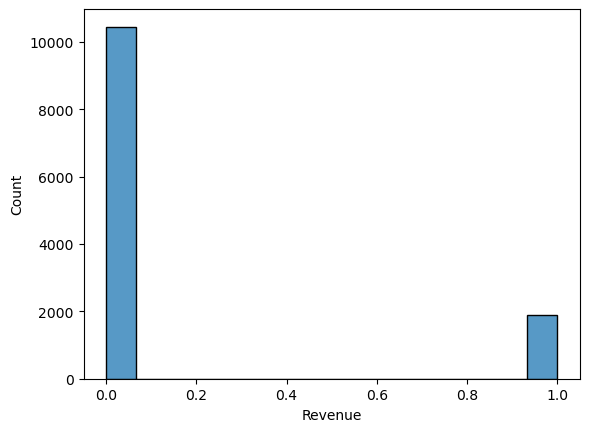

In [13]:
sns.histplot(data=df, x= "Revenue")
plt.show()

### **Conclusion:**

By looking at the graph we notice that we have fare more cases that are 0 than 1 ones. 0 are above 10 000 and 1 are rigth below 2000 meaning that there are fare more cases that not leading to any revenue (the customer haven't bought anything, there was no purchase from the company) than there was some revenue coming in. With other words the target column is inbalanced, menaing that if we we're to train our Machinen learning modeel as i stands right now we would get a modell that predicted more likely than not (majority of the time) that the visitor will not buy anything, there will be no revenue for the company. This is something that we will need to handle later on. We can also see this number if we run the code below:

In [14]:
# Check for inconsistencies in the target variable and correct them
df["Revenue"].value_counts()

Revenue
0    10450
1     1880
Name: count, dtype: int64

### **It appears that the "Revenue" column contains two distinct values: 0 and 1. These values likely represent whether or not a purchase was made during the session. Here's what we can infer from the value counts:**

* There are 10,450 instances where "Revenue" is 0, indicating that in these sessions, no purchase was made.
* There are 1,880 instances where "Revenue" is 1, indicating that in these sessions, a purchase was made.

This suggests that the dataset is imbalanced, with more instances of "Revenue" being 0 compared to 1. Such class imbalance is common in real-world datasets, especially in scenarios like e-commerce where only a small fraction of sessions result in purchases.

To investigate the cause of these numbers and gain a better understanding of the "Revenue" column, you can explore other columns in the dataset. Here are some suggestions:

#### 1. **Page-related features:**

Look at columns like "Administrative", "Informational" and "ProductRelated", along with their duration counterparts. Analyzing the behavior of users who made purchases (Revenue=1) versus those who didn't (Revenue=0) in terms of their interaction with different types of pages might provide insights into their purchase intent.

#### 2. **Page values:**

Check the distribution of "PageValues" for sessions with Revenue=1 versus Revenue=0. "PageValues" represent the average value of the page visited before completing a transaction. Understanding how this metric differs between the two groups can shed light on the effectiveness of different pages in driving conversions.

#### 3. **SpecialDay:**

Investigate how the proximity to special days or holidays affects purchase behavior. Analyze the distribution of "SpecialDay" values for Revenue=1 versus Revenue=0 to see if there's a correlation between special events and purchase likelihood.

#### 4. **TrafficType:** 

Examine the distribution of different traffic types for sessions with Revenue=1 and Revenue=0. Certain traffic sources might be more effective at driving conversions than others.

By exploring these factors, we can gain insights into the patterns and behaviors that contribute to the occurrence of different values in the "Revenue" column. Additionally, this analysis can help identify potential errors in the dataset or areas for further investigation.

In [15]:
# Group the data by "Revenue" and calculate descriptive statistics for page-related features
page_stats = df.groupby("Revenue")[["Administrative", "Informational", "ProductRelated"]].describe()

# Display the statistics
print(page_stats)


        Administrative                                                 \
                 count      mean       std   min  25%  50%  75%   max   
Revenue                                                                 
0              10450.0  2.047751  3.296018 -10.0  0.0  0.0  3.0  27.0   
1               1880.0  3.296809  3.811720 -10.0  0.0  2.0  5.0  26.0   

        Informational            ...            ProductRelated             \
                count      mean  ...  75%   max          count       mean   
Revenue                          ...                                        
0             10450.0  0.452249  ...  0.0  24.0        10450.0  28.780574   
1              1880.0  0.788830  ...  1.0  12.0         1880.0  48.134043   

                                                  
               std  min   25%   50%   75%    max  
Revenue                                           
0        40.908432  0.0   6.0  16.0  35.0  705.0  
1        57.924132  0.0  15.0  29.0  57.0  5

#### **Insight from Descriptive Statistics on Page-Related Features**

The descriptive statistics for page-related features, grouped by "Revenue," provide valuable insights into user behavior on the website and its association with revenue generation.

#### **Administrative Pages:**

* **Count:**

* For non-revenue generating sessions (Revenue = 0), there are 10,450 observations.
* For revenue-generating sessions (Revenue = 1), there are 1,880 observations.

* **Mean:**

* Non-revenue sessions have an average of approximately 2.05 administrative pages visited, while revenue-generating sessions have a slightly higher mean of around 3.30 administrative pages.

* **Standard Deviation (std):**
* The standard deviation is higher for revenue-generating sessions, indicating more variability in the number of administrative pages visited.


* **Minimum (min) and Maximum (max):**
* Both revenue and non-revenue sessions have a minimum value of -10, which may indicate anomalous or missing data.
* The maximum number of administrative pages visited is higher for revenue-generating sessions.

#### **Informational Pages:**

* **Count, Mean, std, min and max:**

* Similar patterns are observed for informational pages as for administrative pages, with slightly higher mean values and standard deviations for revenue-generating sessions.

#### **Product-Related Pages:**

* **Count:**
* Both revenue and non-revenue sessions have a substantial number of observations for product-related pages.

* **Mean:**
* Revenue-generating sessions have a higher mean of approximately 48.13 product-related pages visited, compared to around 28.78 for non-revenue sessions.

**std:**
* The standard deviation is higher for revenue-generating sessions, indicating more variability in the number of product-related pages visited.

* **Minimum and Maximum:**
* Similar to administrative and informational pages, both revenue and non-revenue sessions have a minimum value of 0 and maximum values indicating outliers or highly engaged sessions.

These statistics suggest that users who ultimately generate revenue tend to visit more administrative, informational and product-related pages compared to non-revenue sessions. Additionally, the higher variability in the number of pages visited during revenue-generating sessions may indicate different browsing patterns and potential areas for targeted optimization to enhance conversion rates. Further analysis and segmentation based on user behavior could provide deeper insights for improving website performance and revenue generation.

In [16]:
# Group the data by "Revenue" and calculate descriptive statistics for "PageValues"
page_values_stats = df.groupby("Revenue")["PageValues"].describe()

# Display the statistics
print(page_values_stats)


           count       mean        std  min       25%        50%        75%  \
Revenue                                                                       
0        10450.0   2.054502   9.434679  0.0  0.000000   0.000000   0.000000   
1         1880.0  27.204787  35.084678  0.0  3.660644  16.913567  38.847425   

                max  
Revenue              
0        246.758590  
1        361.763742  


#### **From the descriptive statistics of "PageValues" grouped by "Revenue", we can observe the following insights:**

#### 1. **Mean PageValues:**

* For sessions where "Revenue" is 0 (no purchase), the mean PageValue is approximately 2.05.
* For sessions where "Revenue" is 1 (purchase), the mean PageValue is higher at around 27.20.


#### 2. **Standard Deviation (std):**

* The standard deviation for PageValues is higher for sessions with "Revenue" = 1 compared to "Revenue" = 0. This indicates greater variability in PageValues for sessions where a purchase was made.


#### 3. **Minimum and Maximum PageValues:**

* Both groups (Revenue = 0 and Revenue = 1) have a minimum PageValue of 0, suggesting that some sessions did not generate any page value before a purchase.
* However, the maximum PageValue is much higher for sessions with "Revenue" = 1 (361.76) compared to "Revenue" = 0 (246.76), indicating that some sessions with purchases have higher page values.


#### **Conclusion:**


The difference in mean PageValues between sessions with and without purchases suggests that pages visited before completing a transaction tend to have higher average page values. This implies that certain pages or sequences of pages may be more effective in driving conversions. Understanding these high-value pages can help optimize website design and marketing strategies to enhance conversion rates.

Additionally, the higher variability in PageValues for sessions with purchases indicates that there is a wider range of page values associated with successful conversions. This variability could reflect differences in user behavior, preferences or engagement levels across various sessions that result in purchases.

In summary, analyzing PageValues provides valuable insights into the effectiveness of different pages in driving conversions and can guide decision-making for improving website performance and user experience.

In [17]:
# Group the data by "Revenue" and calculate descriptive statistics for "SpecialDay"
special_day_stats = df.groupby("Revenue")["SpecialDay"].describe()

# Display the statistics
print(special_day_stats)


           count      mean       std  min  25%  50%  75%  max
Revenue                                                      
0        10348.0  0.068110  0.208525  0.0  0.0  0.0  0.0  1.0
1         1859.0  0.023131  0.123993  0.0  0.0  0.0  0.0  1.0


### **From the descriptive statistics of "SpecialDay" grouped by "Revenue", we can observe the following insights:**

#### 1. **Mean SpecialDay:**

* For sessions where "Revenue" is 0 (no purchase), the mean SpecialDay value is approximately 0.068.
* For sessions where "Revenue" is 1 (purchase), the mean SpecialDay value is lower at around 0.023.


#### 2. **Standard Deviation (std):**

* The standard deviation for SpecialDay is higher for sessions with "Revenue" = 0 compared to "Revenue" = 1. This indicates greater variability in SpecialDay values for sessions where no purchase was made.


#### 3. **Minimum and Maximum SpecialDay:**

* Both groups (Revenue = 0 and Revenue = 1) have a minimum SpecialDay value of 0, indicating that most sessions occur on regular days without any special events.
* The maximum SpecialDay value is 1 for both groups, suggesting that some sessions occur on special days or holidays.


#### **Conclusion:**

The difference in mean SpecialDay values between sessions with and without purchases suggests that sessions with purchases are less likely to occur on special days or holidays. This implies that users may be more inclined to make purchases on regular days rather than on special occasions.

The lower mean SpecialDay value for sessions with purchases may indicate that users exhibit different browsing behaviors or purchase intent on regular days compared to special days. Understanding these patterns can help businesses tailor their marketing strategies and promotional activities accordingly.

Additionally, the higher variability in SpecialDay values for sessions without purchases indicates that there is a wider range of SpecialDay occurrences for sessions where no purchase was made. This variability could reflect diverse user behaviors and preferences across different sessions on regular days.

In summary, analyzing SpecialDay values provides insights into the influence of special events and holidays on user purchase behavior. Understanding these dynamics can inform businesses' marketing efforts and help optimize strategies to maximize sales and conversions throughout the year.

In [18]:
# Group the data by "Revenue" and "TrafficType", then calculate the count for each combination
traffic_type_counts = df.groupby(["Revenue", "TrafficType"]).size()

# Display the counts
print(traffic_type_counts)


Revenue  TrafficType
0        1              2193
         2              3074
         3              1878
         4               906
         5               206
         6               394
         7                28
         8               250
         9                38
         10              361
         11              200
         12                1
         13              695
         14               11
         15               38
         16                2
         17                1
         18               10
         19               16
         20              148
1        1               258
         2               839
         3               174
         4               163
         5                54
         6                50
         7                12
         8                93
         9                 4
         10               89
         11               47
         13               43
         14                2
         16           

#### **From the counts of sessions grouped by "Revenue" and "TrafficType", several insights can be derived:**

#### 1. **Distribution of Traffic Types:**

* For sessions where "Revenue" is 0 (no purchase), the most common traffic types are 1, 2 and 3, with counts of 2193, 3074 and 1878 respectively.
* For sessions where "Revenue" is 1 (purchase), traffic types 1 and 2 remain the most common, but there is a notable increase in the count for traffic type 2 compared to sessions with no purchase.


#### 2. **Variability Across Traffic Types:**

* The distribution of traffic types differs between sessions with and without purchases. While some traffic types have similar counts across both groups, others show disparities.

#### 3. **Traffic Types with Low Counts:**

* Some traffic types have very low counts in both groups, such as traffic types 12, 16, 17 and 18. This suggests that these traffic sources contribute minimally to overall session counts, regardless of purchase outcome.


#### 4. **Differential Impact on Revenue:**

* Traffic types with higher counts in sessions where "Revenue" is 1 may indicate traffic sources that are more effective at driving conversions. For example, traffic type 2 has a substantially higher count in sessions with purchases compared to sessions without purchases.


#### **Conclusion:**

The distribution of traffic types varies between sessions with and without purchases, suggesting that different sources of traffic may have varying degrees of impact on conversion rates. Traffic types that exhibit higher counts in sessions with purchases could represent channels that are more successful at driving conversions.

Businesses can use this insight to prioritize and allocate resources to traffic sources that have demonstrated effectiveness in generating revenue. Additionally, analyzing traffic types with low counts can help identify underperforming channels that may require further optimization or reconsideration in marketing strategies.

Understanding the relationship between traffic sources and purchase behavior can inform marketing efforts, allowing businesses to focus on strategies that maximize conversion rates and ultimately contribute to higher revenue generation.

### From the analysis of different features in relation to revenue, several insights can be drawn:

#### 1. **Page-Related Features:**

* Sessions where revenue is 1 (indicating a purchase) tend to have higher mean values for administrative, informational and product-related pages visited compared to sessions where revenue is 0.
* This suggests that users who ultimately make a purchase tend to engage with more pages across different categories, indicating a higher level of interaction with the website.

#### 2.**Page Values:**

* The mean page value for sessions with revenue=1 is higher compared to sessions with revenue=0.
* This implies that pages visited before completing a transaction have higher average values for sessions where a purchase is made, indicating that these pages contribute more to conversion.

#### 3. **SpecialDay:**

* Sessions with revenue=1 have a lower mean value for "SpecialDay" compared to sessions with revenue=0.
* This suggests that purchases are less likely to occur on special days or holidays, as indicated by lower average values for "SpecialDay" in sessions where revenue is 1.

#### 4. **Traffic Type:**

* The distribution of traffic types varies between sessions with revenue=1 and revenue=0, with some traffic types showing higher counts in sessions where purchases are made.
* This indicates that certain traffic sources may be more effective at driving conversions, as evidenced by higher counts of specific traffic types in sessions where revenue is 1.


#### **Conclusion:**

* Users who ultimately make purchases tend to engage with more pages across different categories, suggesting a higher level of interaction with the website before completing a transaction.
* Pages visited before completing a transaction have higher average values for sessions where a purchase is made, indicating their importance in driving conversions.
* Purchases are less likely to occur on special days or holidays, as indicated by lower average values for "SpecialDay" in sessions where revenue is 1.
* Certain traffic sources may be more effective at driving conversions, as evidenced by higher counts of specific traffic types in sessions where revenue is 1.


Overall, these insights can help businesses optimize their website design, content and marketing strategies to enhance user engagement, improve conversion rates and ultimately increase revenue. Understanding the factors that influence purchase behavior is necessary for businesses to tailor their approach and maximize the effectiveness of their online platforms.

In [19]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

### Let's explore other columns:

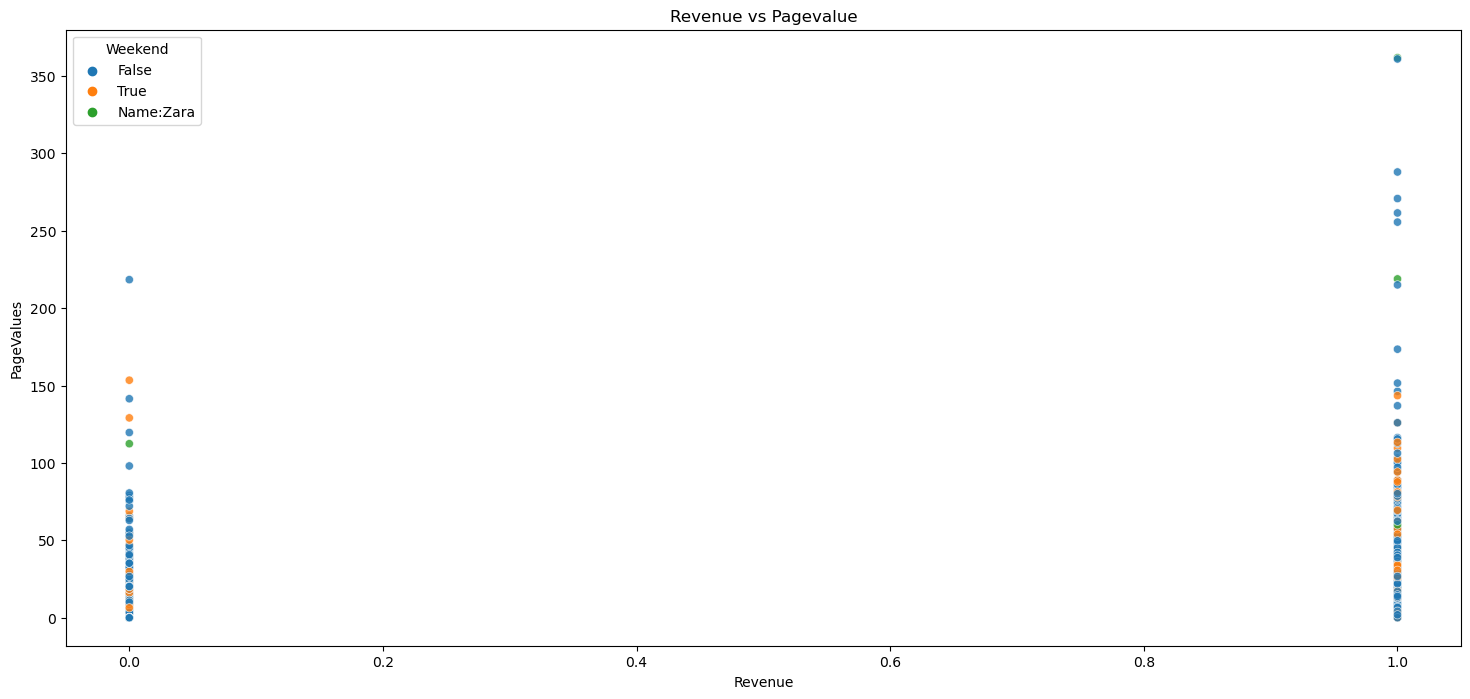

In [20]:
plt.figure(figsize=(18,8))
temp_df = df.sample(4000)
sns.scatterplot(x=temp_df.Revenue, y=temp_df.PageValues, hue=temp_df.Weekend, alpha=0.8)
plt.title("Revenue vs Pagevalue")
plt.show()

Upon detecting an anomaly labeled as "Name:Zara," we addressed this issue by executing the following code snippet:

In [21]:
# Replace "Zara" with NaN in the "Weekend" column for imputing later
df["Weekend"] = df["Weekend"].replace("Name:Zara", np.nan)

# Check the updated "Weekend" column
print(df["Weekend"].value_counts())

Weekend
False    9273
True     2868
Name: count, dtype: int64


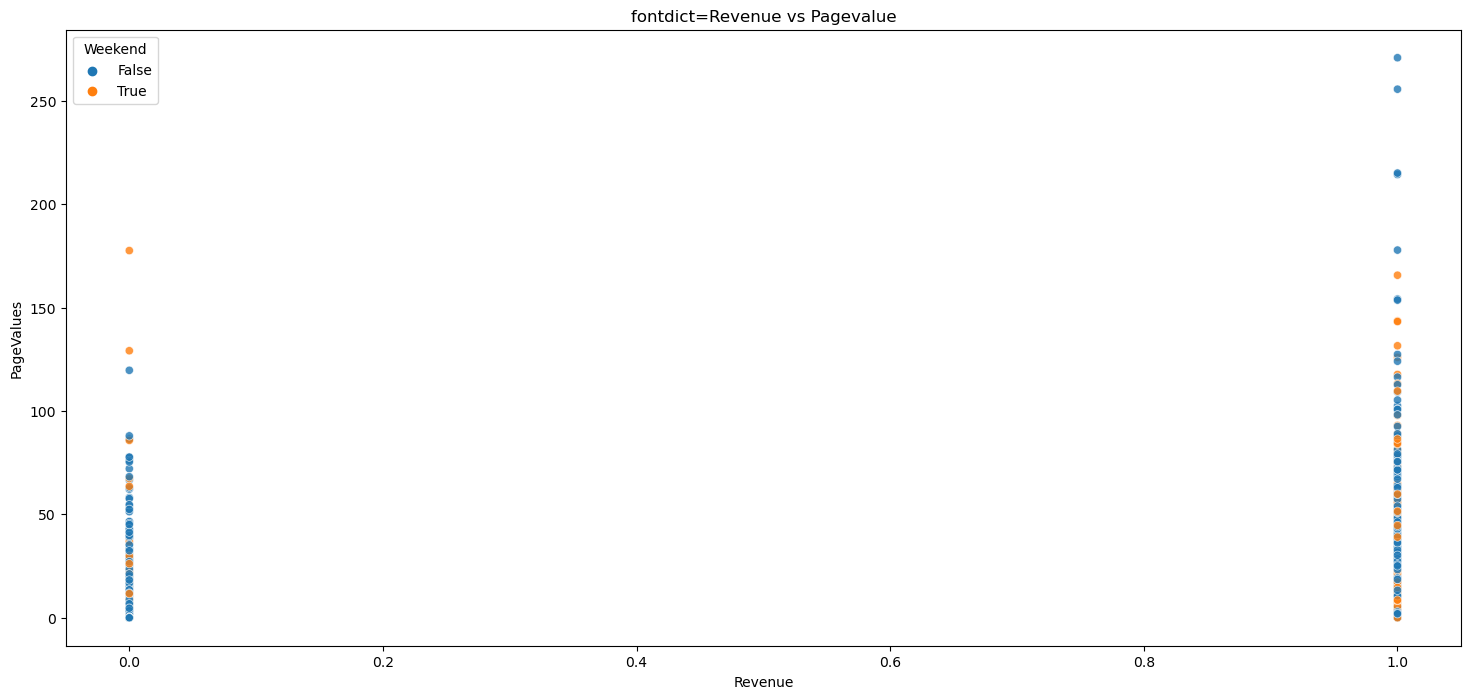

In [22]:
plt.figure(figsize=(18,8))
temp_df = df.sample(4000)
sns.scatterplot(x=temp_df.Revenue, y=temp_df.PageValues, hue=temp_df.Weekend, alpha=0.8)
plt.title("fontdict=Revenue vs Pagevalue")
plt.show()

In [23]:
# Calculate descriptive statistics for "PageValues" grouped by "Revenue" and "Weekend"
page_values_stats = df.groupby(["Revenue", "Weekend"])["PageValues"].describe()

# Display the statistics
print(page_values_stats)


                  count       mean        std  min       25%        50%  \
Revenue Weekend                                                           
0       False    7922.0   2.067019   9.287275  0.0  0.000000   0.000000   
        True     2374.0   1.934230   9.548623  0.0  0.000000   0.000000   
1       False    1351.0  26.974326  34.680824  0.0  3.735234  17.079782   
        True      494.0  27.245726  32.417450  0.0  3.200836  16.811398   

                       75%         max  
Revenue Weekend                         
0       False     0.000000  246.758590  
        True      0.000000  177.528825  
1       False    38.269996  360.953384  
        True     39.653974  204.007949  


Upon examining the graph, it becomes apparent that there is a positive correlation between the PageValues and revenue. Higher values of PageValues tend to correspond with increased revenue generation. Notably, there is a greater concentration of data points on the revenue side 1, accompanied by a larger number of outliers compared to the 0 revenue side. This observation aligns with our earlier findings when analyzing patterns in Page-related features and PageValues.

#### **we can derive the following insights:**

#### 1. **PageValues Analysis by Revenue and Weekend:**

* **For sessions where no revenue was generated (Revenue=0):**
    * The mean "PageValues" for sessions on weekdays (Weekend=False) is approximately 2.07, with a standard deviation of around 9.29.
    * The mean "PageValues" for sessions on weekends (Weekend=True) is slightly lower, around 1.93, with a standard deviation of approximately 9.55.

* **For sessions where revenue was generated (Revenue=1):**
    * The mean "PageValues" for sessions on weekdays (Weekend=False) is higher, around 26.97, with a standard deviation of about 34.68.
    * The mean "PageValues" for sessions on weekends (Weekend=True) is similar, approximately 27.25, with a standard deviation of around 32.42.

#### 2. **Conclusions:**

* The mean "PageValues" for sessions with revenue (Revenue=1) is substantially higher compared to sessions without revenue (Revenue=0), regardless of whether they occur on weekdays or weekends.
* Sessions with revenue tend to have higher variability in "PageValues" compared to sessions without revenue, as indicated by the larger standard deviations.
* There doesn't seem to be a difference in "PageValues" between weekday and weekend sessions within the same revenue category.


#### 3. **Comparison with Previous Insights:**

* These findings align with the earlier insights derived from analyzing page-related features and page values individually. Specifically, the "PageValues" tend to be higher for sessions where revenue is generated, indicating that pages visited before completing a transaction have a higher average value.
* The distinction between weekday and weekend sessions further emphasizes the importance of "PageValues" in predicting revenue, as it remains across different days of the week.


Overall, the analysis provides consistent indication that "PageValues" plays a role in predicting revenue, with higher values associated with sessions where purchases are made. These insights reinforce the importance of considering "PageValues" as a key metric for understanding user behavior and predicting revenue in e-commerce settings.

<Axes: xlabel='Weekend', ylabel='Revenue'>

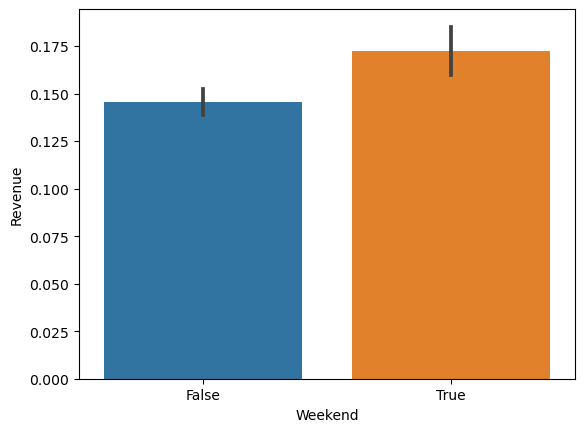

In [24]:
sns.barplot(data=df, x="Weekend", y="Revenue")

<Axes: xlabel='SpecialDay', ylabel='Revenue'>

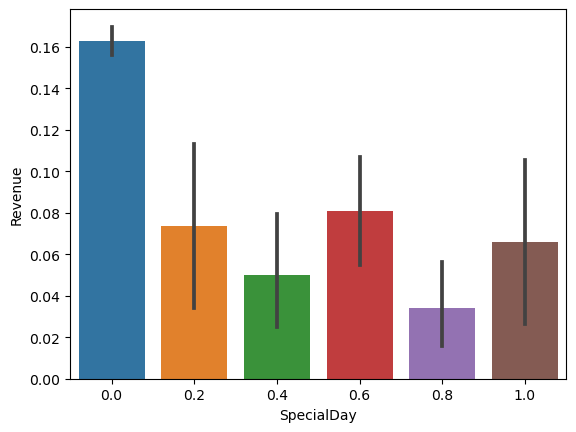

In [25]:
sns.barplot(data=df, x="SpecialDay", y="Revenue")

In [26]:
# Calculate the mean revenue for each "SpecialDay" value
special_day_revenue_mean = df.groupby("SpecialDay")["Revenue"].mean()

# Display the mean revenue for each "SpecialDay" value
print(special_day_revenue_mean)


SpecialDay
0.0    0.162702
0.2    0.073446
0.4    0.050000
0.6    0.080925
0.8    0.034268
1.0    0.065789
Name: Revenue, dtype: float64


Based on the information provided and the analysis conducted, the "SpecialDay" feature likely represents the closeness of the visit date to a special day or holiday. Here's what each value could signify:

0.0: Indicates that the visit date is not close to any special day or holiday.

0.2: Likely represents a low level of proximity to a special day or holiday, such as being within two tenths of the distance to the nearest special day.

0.4: Indicates a moderate level of proximity to a special day or holiday, approximately halfway between two special days.

0.6: Represents a higher level of proximity to a special day or holiday, suggesting that the visit date is closer to a special day than the values 0.2 and 0.4.

0.8: Indicates a very high level of proximity to a special day or holiday, implying that the visit date is very close to a special day or holiday.

1.0: Likely signifies that the visit date coincides exactly with a special day or holiday.

The mean revenue for each of these "SpecialDay" values provides insight into how close the visit dates to special days or holidays impact revenue generation. However, without explicit information about the dataset, such as the specific special days or holidays considered and their significance, it's challenging to provide precise interpretations. Nonetheless, the analysis can still offer valuable insights into the relationship between special days and revenue generation, guiding marketing strategies and promotional efforts.

From the output, we can observe the mean revenue for each value of the "SpecialDay" column:

When "SpecialDay" is 0.0, the mean revenue is approximately 0.1627.
When "SpecialDay" is 0.2, the mean revenue is approximately 0.0734.
When "SpecialDay" is 0.4, the mean revenue is approximately 0.0500.
When "SpecialDay" is 0.6, the mean revenue is approximately 0.0809.
When "SpecialDay" is 0.8, the mean revenue is approximately 0.0343.
When "SpecialDay" is 1.0, the mean revenue is approximately 0.0658.

Insights:

Higher "SpecialDay" values don't necessarily lead to higher revenue: Contrary to expectations, "SpecialDay" values closer to 1.0 (indicating proximity to a special day or holiday) do not consistently result in higher mean revenue. For instance, "SpecialDay" values of 0.4 and 0.6 have lower mean revenues compared to "SpecialDay" values of 0.0 and 1.0.

Variability in mean revenue: There is a notable variability in mean revenue across different "SpecialDay" values. This suggests that while some special days may lead to increased revenue, others may not have a impact or could even result in lower revenue.

Potential marketing opportunities: Analyzing mean revenue in relation to "SpecialDay" values can help identify opportunities for targeted marketing strategies. Understanding which special days or events contribute most to revenue can guide marketing efforts and promotional campaigns.

Conclusions:

The relationship between "SpecialDay" values and revenue is complex and nonlinear. Simply being closer to a special day does not necessarily lead to higher revenue. Businesses should analyze specific special days and events individually to determine their impact on revenue and tailor marketing strategies accordingly. Further analysis, possibly considering additional factors such as promotions or advertising campaigns during special days, may provide deeper insights into the observed patterns and help optimize revenue generation strategies.

<a id="sec-outliers"></a>
### Manual Search For Outliers with Boxplots

This is a box plot we can see the median and we can see the minimum and maximum range of our data and everything that falls outside of those whiskers is going to be an outlier and we can see the outliers here are points

In [27]:
px.box(data_frame=df,x="Administrative_Duration", title="Outliers in Administrative_Duration")

In [28]:
px.box(data_frame=df,x="Administrative", title="Outliers in Administrative")

In [29]:
px.box(data_frame=df,x="Informational", title="Outliers in Informational")

In [30]:
px.box(data_frame=df,x="Informational_Duration", title="Outliers in Informational_Duration")

In [31]:
px.box(data_frame=df,x="ProductRelated", title="Outliers in ProductRelated")

In [32]:
px.box(data_frame=df,x="ProductRelated_Duration", title="Outliers in ProductRelated_Duration")

In [33]:
px.box(data_frame=df,x="BounceRates", title="Outliers in BonuceRates")

In [34]:
px.box(data_frame=df,x="ExitRates", title="Outliers in ExitRates")

In [35]:
px.box(data_frame=df,x="PageValues", title="Outliers in PageValues")

In [36]:
px.box(data_frame=df,x="SpecialDay", title="Outliers in SpeacialDay")

In [37]:
px.box(data_frame=df,x="Month", title="Outliers in Month")

In [38]:
px.box(data_frame=df,x="OperatingSystems", title="Outliers in OperatingSystems")

In [39]:
px.box(data_frame=df,x="Browser", title="Outliers in Browser")

In [40]:
px.box(data_frame=df,x="Region", title="Outliers in Region")

In [41]:
px.box(data_frame=df,x="TrafficType", title="Outliers in TrafficType")

In [42]:
# find the limits
upper_limit = df["Administrative"].mean() + 3*df["Administrative"].std()
lower_limit = df["Administrative"].mean() - 3*df["Administrative"].std()

print("upper limit:" , upper_limit)
print("lower limit:" , lower_limit)

upper limit: 12.466007290782311
lower limit: -7.989608264018322


In [43]:
# find outliers
df.loc[(df["Administrative"] > upper_limit) | (df["Administrative"] < lower_limit)]

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
149,-8,0.000000,0,0.000000,11,316.666667,0.000000,0.027273,0.000000,0.8,Feb,2,2.0,2.0,1,Returning_Visitor,False,0
201,-10,0.000000,0,0.000000,5,43.000000,0.000000,0.040000,0.000000,0.0,Mar,1,1.0,1.0,9,Returning_Visitor,True,0
248,16,155.631313,0,0.000000,32,908.013456,0.005000,0.018053,4.368516,0.0,Mar,2,2.0,3.0,2,Returning_Visitor,False,1
282,13,1249.809524,4,205.000000,36,1626.625433,0.010638,0.026186,6.831792,0.0,Mar,3,2.0,2.0,3,Returning_Visitor,False,0
369,-9,7.000000,0,0.000000,27,559.400000,0.014815,0.030453,0.000000,0.0,Mar,2,4.0,4.0,3,Returning_Visitor,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11988,14,228.748539,6,121.583333,336,12166.694240,0.000000,0.012144,0.067050,0.0,Nov,2,2.0,7.0,2,Returning_Visitor,False,1
12133,-8,97.000000,3,103.250000,16,1509.500000,0.000000,0.018933,0.000000,0.0,Nov,2,2.0,1.0,2,Returning_Visitor,False,0
12178,26,1561.717567,9,503.722222,183,9676.093180,0.011055,0.014200,19.567464,0.0,Nov,3,2.0,2.0,13,Returning_Visitor,False,1
12233,13,399.750000,3,47.750000,61,1458.993056,0.001786,0.016552,17.497219,0.0,Nov,1,1.0,1.0,2,New_Visitor,False,0


We have identified the presence of outliers in the dataset.

In [44]:
# Find all duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

# Display duplicate rows
print("Duplicate Rows:")
print(duplicate_rows)


Duplicate Rows:
       Administrative  Administrative_Duration  Informational  \
85                  0                      0.0              0   
132                 0                      0.0              0   
158                 0                      0.0              0   
178                 0                      0.0              0   
252                 0                      0.0              0   
...               ...                      ...            ...   
11934               0                      0.0              0   
11938               0                      0.0              0   
12159               0                      0.0              0   
12180               0                      0.0              0   
12185               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
85                        0.0               1                      0.0   
132                       0.0               1          

The DataFrame contains 151 duplicate rows

In [45]:
# Find duplicate rows in the entire dataset
duplicate_rows = df[df.duplicated()]

# Display duplicate rows
print("Duplicate Rows:")
print(duplicate_rows)


Duplicate Rows:
       Administrative  Administrative_Duration  Informational  \
158                 0                      0.0              0   
178                 0                      0.0              0   
418                 0                      0.0              0   
512                 0                      0.0              0   
554                 0                      0.0              0   
...               ...                      ...            ...   
11934               0                      0.0              0   
11938               0                      0.0              0   
12159               0                      0.0              0   
12180               0                      0.0              0   
12185               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
158                       0.0               1                      0.0   
178                       0.0               1          

The difference between the two code snippets lies in the keep parameter of the duplicated() function.

In the first code snippet:

In [46]:
duplicate_rows = df[df.duplicated(keep=False)]

The keep=False parameter means that all occurrences of a duplicated row, including the first occurrence, will be considered as duplicates and included in the result.

In the second code snippet:

In [47]:
duplicate_rows = df[df.duplicated()]

The keep=False parameter means that all occurrences of a duplicated row, including the first occurrence, will be considered as duplicates and included in the result.

In the second code snippet:

In [48]:
duplicate_rows = df[df.duplicated()]

The default value of keep is first, which means only the first occurrence of each duplicated row is considered as a duplicate and subsequent occurrences are not included in the result. This is why the output shows fewer duplicate rows compared to the first snippet.

If we want to include all occurrences of duplicated rows in the result, we need to set keep=False, as in the first code snippet.

#### **Conclusion:**

In the absence of specific criteria or additional context for defining outliers within this e-commerce dataset, drawing meaningful conclusions about them becomes challenging.

Understanding the outliers and duplicated rows within the dataset requires more nuanced analysis and contextual information. For instance, it's plausible that multiple customers visiting the website might share the same operating system, exhibit similar durations for product-related activities or access the site during the same time frame (weekend, month). These variations may not necessarily indicate outliers but could reflect legitimate differences in customer behavior.

To extract actionable insights from these outliers and duplicates, a clearer definition of what constitutes outliers and duplicates within the context of the dataset is essential. Moreover, additional contextual information about the dataset and the e-commerce platform would facilitate a more comprehensive analysis.

In summary, while the presence of outliers and duplicates warrants attention, drawing definitive conclusions about their impact on the dataset without further contextual information may be premature. Thus, the conclusion that more data is needed to derive meaningful insights about outliers and duplicates remains valid.

<a id="sec-anomalies"></a>
### **Addressing Anomalies in the Dataset**
Now, we proceed to rectify the anomalies present within the dataset.

We will begin by examining the correlation between our target column, revenue and other features in the dataset.

The correlation coefficients between the "Revenue" column and other features in the dataset provide insights into the relationships between these variables. Here are some observations and conclusions we can draw from 

#### **the correlation values:**

##### **Strong Positive Correlation:**

"PageValues" has the highest positive correlation with "Revenue" (0.487). This indicates that higher page values tend to be associated with higher revenue, suggesting that pages with higher values are more likely to lead to successful conversions.
"ProductRelated" and "ProductRelated_Duration" also show moderate positive correlations (0.156 and 0.150 respectively) with "Revenue", indicating that more product-related pages visited and longer durations spent on those pages tend to result in higher revenue.

##### **Weak Positive Correlation:**

"Administrative" and "Informational" pages have weak positive correlations with "Revenue" (0.132 and 0.095 respectively). This suggests that while there is some positive association between these page types and revenue, it is not as strong as with product-related pages.

##### **Weak Negative Correlation:**

"ExitRates" has a weak negative correlation (-0.205) with "Revenue". This suggests that higher exit rates are associated with lower revenue, indicating that visitors who exit the site more frequently are less likely to generate revenue.

##### **Other Variables:**

"Month", "Weekend", "Browser", "SpecialDay" and "VisitorType" also show some level of correlation with "Revenue", though these correlations are relatively weak compared to other variables.
Overall, these correlation values provide valuable insights into the factors influencing revenue generation on the website. They can help in identifying key areas for improvement or optimization to maximize revenue, such as optimizing high-value pages, reducing exit rates and potentially leveraging insights from visitor behavior on different types of pages.


### **Handling Anomalies in the Month Column**

Reference to the decision to change the month name: https://wmich.edu/writing/rules/dates

In [49]:
# Define a dictionary to map abbreviated month names to full month names
month_mapping = {
    "Mar": "March",
    "Turc": "April",
    "Jul": "July",
    "Sep": "Sept",
    
    
}

# Replace the abbreviated month names with their full month names
df["Month"] = df["Month"].replace(month_mapping)

# Print the unique values in the "Month" column after correction
print('Unique values in the "Month" column after correction:')
print(df["Month"].unique())


Unique values in the "Month" column after correction:
['Feb' 'March' 'May' 'April' 'Oct' 'June' 'July' 'Aug' 'Nov' 'Sept' 'Dec']


In [50]:
# Print count of unique values for each column, including NaN values
for column in df.columns:
    print("Column:", column)
    print(df[column].value_counts(dropna=False))  # Include NaN values
    print()

Column: Administrative
Administrative
 0     5704
 1     1341
 2     1101
 3      909
 4      757
 5      574
 6      428
 7      334
 8      285
 9      223
 10     153
 11     102
 12      84
 13      56
 14      44
 15      38
 16      24
-8       17
 17      16
-5       16
-6       16
-9       15
-7       14
-1       14
-3       13
 18      11
 19       6
-2        6
-10       6
-4        6
 24       4
 22       4
 23       3
 21       2
 20       2
 27       1
 26       1
Name: count, dtype: int64

Column: Administrative_Duration
Administrative_Duration
0.000000      5898
4.000000        56
5.000000        53
7.000000        45
11.000000       42
              ... 
167.500000       1
33.466667        1
50.373333        1
50.933333        1
150.357143       1
Name: count, Length: 3345, dtype: int64

Column: Informational
Informational
0     9699
1     1041
2      728
3      380
4      222
5       99
6       78
7       36
9       15
8       14
10       7
12       5
14       2
16    

Convert categorical columns in the dataset to numeric to facilitate correlation analysis.

In [51]:
# Define a function to map month names to numerical values
def map_month(month):
    month_map = {
        "Feb": 2, "March": 3, "April": 4, "May": 5, "June": 6,
        "July": 7, "Aug": 8, "Sept": 9, "Oct": 10, "Nov": 11, "Dec": 12
    }
    return month_map.get(month, 0)  # Return 0 if month is not found

# Apply the mapping to the "Month" column
df["Month"] = df["Month"].apply(map_month)

In [52]:
# Print count of unique values for each column, including NaN values
for column in df.columns:
    print("Column:", column)
    print(df[column].value_counts(dropna=False))  # Include NaN values
    print()

Column: Administrative
Administrative
 0     5704
 1     1341
 2     1101
 3      909
 4      757
 5      574
 6      428
 7      334
 8      285
 9      223
 10     153
 11     102
 12      84
 13      56
 14      44
 15      38
 16      24
-8       17
 17      16
-5       16
-6       16
-9       15
-7       14
-1       14
-3       13
 18      11
 19       6
-2        6
-10       6
-4        6
 24       4
 22       4
 23       3
 21       2
 20       2
 27       1
 26       1
Name: count, dtype: int64

Column: Administrative_Duration
Administrative_Duration
0.000000      5898
4.000000        56
5.000000        53
7.000000        45
11.000000       42
              ... 
167.500000       1
33.466667        1
50.373333        1
50.933333        1
150.357143       1
Name: count, Length: 3345, dtype: int64

Column: Informational
Informational
0     9699
1     1041
2      728
3      380
4      222
5       99
6       78
7       36
9       15
8       14
10       7
12       5
14       2
16    

In [53]:
# Apply label encoding followed by one-hot encoding for "VisitorType"
label_encoder = LabelEncoder()
df["VisitorType"] = label_encoder.fit_transform(df["VisitorType"])
one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
visitor_type_encoded = one_hot_encoder.fit_transform(df[["VisitorType"]])
visitor_type_categories = ["VisitorType_" + str(i) for i in label_encoder.classes_]
visitor_type_df = pd.DataFrame(visitor_type_encoded, columns=visitor_type_categories)
df = pd.concat([df, visitor_type_df], axis=1)

# Handling erroneous values in "Weekend" column
# Replacing "True" and "False" with 1 and 0 respectively
df["Weekend"] = df["Weekend"].replace({"True": 1, "False": 0})

# Convert "Weekend" column to numeric (float)
df["Weekend"] = df["Weekend"].astype(float)

# Drop original categorical columns
df.drop(["VisitorType"], axis=1, inplace=True)

In [54]:
# Print count of unique values for each column, including NaN values
for column in df.columns:
    print("Column:", column)
    print(df[column].value_counts(dropna=False))  # Include NaN values
    print()

Column: Administrative
Administrative
 0     5704
 1     1341
 2     1101
 3      909
 4      757
 5      574
 6      428
 7      334
 8      285
 9      223
 10     153
 11     102
 12      84
 13      56
 14      44
 15      38
 16      24
-8       17
 17      16
-5       16
-6       16
-9       15
-7       14
-1       14
-3       13
 18      11
 19       6
-2        6
-10       6
-4        6
 24       4
 22       4
 23       3
 21       2
 20       2
 27       1
 26       1
Name: count, dtype: int64

Column: Administrative_Duration
Administrative_Duration
0.000000      5898
4.000000        56
5.000000        53
7.000000        45
11.000000       42
              ... 
167.500000       1
33.466667        1
50.373333        1
50.933333        1
150.357143       1
Name: count, Length: 3345, dtype: int64

Column: Informational
Informational
0     9699
1     1041
2      728
3      380
4      222
5       99
6       78
7       36
9       15
8       14
10       7
12       5
14       2
16    

### Handling Anomalies in Administrative and BounceRates Columns

In [55]:
# Replace negative values in the "Administrative" column with NaN for later imputation
df["Administrative"] = df["Administrative"].apply(lambda x: np.nan if x < 0 else x)

# Replace negative values in the "BounceRates" column with NaN for later imputation
df["BounceRates"] = df["BounceRates"].apply(lambda x: np.nan if x < 0 else x)


### Converting the Specialday Column to Binary Values

In [56]:
# Create Special Days feature
# Special Days: Similarly, the SpecialDay column should ideally have binary values indicating whether the visit occurred on a special day (1) or not (0).
df["SpecialDay"] = (df["SpecialDay"] != 0).astype(int)

In [57]:
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,0.0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0,2,1,NaN,1.0,1,0.0,0,0.0,0.0,1.0
1,0.0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0,2,2,2.0,NaN,2,0.0,0,0.0,0.0,1.0
2,0.0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0,2,4,1.0,NaN,3,0.0,0,0.0,0.0,1.0
3,0.0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0,2,3,2.0,2.0,4,0.0,0,0.0,0.0,1.0
4,0.0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0,2,3,3.0,1.0,4,1.0,0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3.0,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0,12,4,6.0,NaN,1,1.0,0,0.0,0.0,1.0
12326,0.0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0,11,3,2.0,1.0,8,1.0,0,0.0,0.0,1.0
12327,0.0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0,11,3,2.0,1.0,13,1.0,0,0.0,0.0,1.0
12328,4.0,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0,11,2,2.0,3.0,11,0.0,0,0.0,0.0,1.0


In [58]:
# look if there is any difference in the output when moveing up this chaning specialday values 
df.corr()["Revenue"].sort_values(ascending=False)

Revenue                          1.000000
PageValues                       0.486922
ProductRelated                   0.156433
ProductRelated_Duration          0.149705
Administrative                   0.135413
Month                            0.126867
VisitorType_New_Visitor          0.104667
Informational                    0.095263
Informational_Duration           0.070084
Weekend                          0.031419
Browser                          0.021462
VisitorType_Other                0.005562
TrafficType                     -0.004362
Region                          -0.011213
OperatingSystems                -0.013649
Administrative_Duration         -0.014322
BounceRates                     -0.020177
SpecialDay                      -0.080841
VisitorType_Returning_Visitor   -0.103857
ExitRates                       -0.205343
Name: Revenue, dtype: float64

In [59]:
# Print count of unique values for each column, including NaN values
for column in df.columns:
    print("Column:", column)
    print(df[column].value_counts(dropna=False))  # Include NaN values
    print()

Column: Administrative
Administrative
0.0     5704
1.0     1341
2.0     1101
3.0      909
4.0      757
5.0      574
6.0      428
7.0      334
8.0      285
9.0      223
10.0     153
NaN      123
11.0     102
12.0      84
13.0      56
14.0      44
15.0      38
16.0      24
17.0      16
18.0      11
19.0       6
24.0       4
22.0       4
23.0       3
21.0       2
20.0       2
27.0       1
26.0       1
Name: count, dtype: int64

Column: Administrative_Duration
Administrative_Duration
0.000000      5898
4.000000        56
5.000000        53
7.000000        45
11.000000       42
              ... 
167.500000       1
33.466667        1
50.373333        1
50.933333        1
150.357143       1
Name: count, Length: 3345, dtype: int64

Column: Informational
Informational
0     9699
1     1041
2      728
3      380
4      222
5       99
6       78
7       36
9       15
8       14
10       7
12       5
14       2
16       1
11       1
24       1
13       1
Name: count, dtype: int64

Column: Informa

### Exploring Correlation

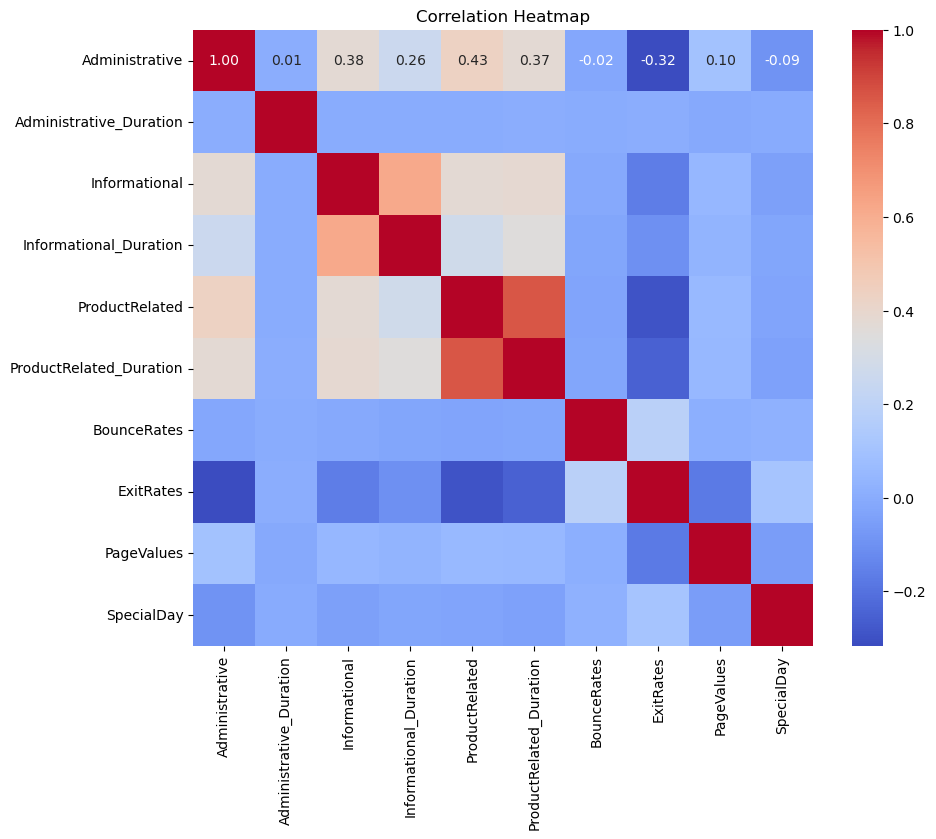

In [60]:
# Compute the correlation matrix
correlation = df.iloc[:, :10].corr()  # Assuming the first 10 columns are the ones we want to analyze

# Set the size of the plot
plt.figure(figsize=(10, 8))

# Create a heatmap of the correlation matrix
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

# Add a title
plt.title("Correlation Heatmap")

# Display the plot
plt.show()

In [61]:
df.corr()["Revenue"].sort_values(ascending=False)

Revenue                          1.000000
PageValues                       0.486922
ProductRelated                   0.156433
ProductRelated_Duration          0.149705
Administrative                   0.135413
Month                            0.126867
VisitorType_New_Visitor          0.104667
Informational                    0.095263
Informational_Duration           0.070084
Weekend                          0.031419
Browser                          0.021462
VisitorType_Other                0.005562
TrafficType                     -0.004362
Region                          -0.011213
OperatingSystems                -0.013649
Administrative_Duration         -0.014322
BounceRates                     -0.020177
SpecialDay                      -0.080841
VisitorType_Returning_Visitor   -0.103857
ExitRates                       -0.205343
Name: Revenue, dtype: float64

"Administrative" pages still have a weak positive correlations with "Revenue" but an intressting change has occured, if we look closely we can see a sligth increase going from **0.132** to **0.135**, this shift has most likely been to the effect of transforming the negative values to NaN values that we did earlier.

### Feature Engineering

Feature engineering is the process of creating new features (columns) by transforming/combining existing features or by incorporating data from external sources.

One feature engineering approach we can consider is creating interaction features between different columns. For example, we can create new features by combining the counts or durations of different types of activities. Here's why this approach could be beneficial:

1. **Increased Predictive Power:**

By combining information from multiple features, we can potentially capture more complex patterns in the data that could enhance the predictive power of our model. For example, the combination of the count of administrative, informational and product-related activities might provide more insights into user behavior than considering each type of activity in isolation.

2. **Capture Synergistic Effects:**

Certain combinations of activities or features might have synergistic effects on the likelihood of revenue generation. For instance, a high number of product-related activities coupled with a long session duration might indicate strong purchase intent, which could be captured through interaction features.

3. **Dimensionality Reduction:**

Instead of using all individual features, creating interaction features allows us to reduce the dimensionality of the dataset while still retaining important information. This can help mitigate issues related to the curse of dimensionality and improve model efficiency.

4. **Domain Understanding:**

Feature engineering based on domain understanding can help us create features that are more meaningful and relevant to the problem at hand. By combining features that are intuitively related, we can leverage our knowledge of the domain to engineer features that capture important aspects of user behavior.

5. **Improved Model Interpretability:**

Interaction features can also aid in model interpretability by providing insights into the relationships between different features and the target variable. This can help stakeholders better understand the factors influencing the outcome of interest, such as revenue generation.

Overall, creating interaction features offers a powerful way to extract more information from the dataset and potentially improve the performance of machine learning models in predicting revenue generation or other relevant outcomes.

In [62]:
# Create interaction features
df["PageViews_Administrative"] = df["PageValues"] * df["Administrative"]
df["PageViews_Informational"] = df["PageValues"] * df["Informational"]
df["PageViews_ProductRelated"] = df["PageValues"] * df["ProductRelated"]

df["Duration_Administrative"] = df["ProductRelated_Duration"] * df["Administrative"]
df["Duration_Informational"] = df["ProductRelated_Duration"] * df["Informational"]
df["Duration_ProductRelated"] = df["ProductRelated_Duration"] * df["ProductRelated"]

# Drop original columns used to create interaction features
df.drop(["Administrative", "Informational", "ProductRelated"], axis=1, inplace=True)


In this code:

We create interaction features by multiplying different columns together, such as PageValues with Administrative, Informational and ProductRelated and ProductRelated_Duration with Administrative, Informational and ProductRelated. These interaction features capture the combined effects of the original features and can potentially provide more insights into user behavior.
We then drop the original columns used to create the interaction features to avoid multicollinearity issues and reduce dimensionality.

In [63]:
df

,Administrative_Duration,Informational_Duration,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,...,Revenue,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor,PageViews_Administrative,PageViews_Informational,PageViews_ProductRelated,Duration_Administrative,Duration_Informational,Duration_ProductRelated
0,0.0,0.0,0.000000,0.200000,0.200000,0.000000,0,2,1,NaN,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000
1,0.0,0.0,64.000000,0.000000,0.100000,0.000000,0,2,2,2.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,128.000000
2,0.0,0.0,0.000000,0.200000,0.200000,0.000000,0,2,4,1.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000
3,0.0,0.0,2.666667,0.050000,0.140000,0.000000,0,2,3,2.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,5.333333
4,0.0,0.0,627.500000,0.020000,0.050000,0.000000,0,2,3,3.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,6275.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,145.0,0.0,1783.791667,0.007143,0.029031,12.241717,0,12,4,6.0,...,0,0.0,0.0,1.0,36.725152,0.0,648.811025,5351.375001,0.0,94540.958351
12326,0.0,0.0,465.750000,0.000000,0.021333,0.000000,0,11,3,2.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,2328.750000
12327,0.0,0.0,184.250000,0.083333,0.086667,0.000000,0,11,3,2.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.0,1105.500000
12328,75.0,0.0,346.000000,0.000000,0.021053,0.000000,0,11,2,2.0,...,0,0.0,0.0,1.0,0.000000,0.0,0.000000,1384.000000,0.0,5190.000000


#### **Changes made when creating the interaction features:**

#### 1. **Administrative Duration, Informational Duration, ProductRelated Duration:** 

These columns represent the duration spent on administrative, informational and product-related pages, respectively. These values are calculated by multiplying the duration spent on each page category (Administrative, Informational, ProductRelated) with the corresponding number of page views (PageValues).

#### 2. **PageViews_Administrative, PageViews_Informational, PageViews_ProductRelated:**

These columns represent the product of the number of page views (PageValues) and the number of pages visited within each page category (Administrative, Informational, ProductRelated). They provide an indication of user engagement within each page category.

#### 3. **Duration_Administrative, Duration_Informational, Duration_ProductRelated:**

These columns represent the product of the duration spent on pages within each page category (Administrative, Informational, ProductRelated) and the number of pages visited within the respective category (PageValues). They provide an indication of the total time spent on each page category.

#### **Drop Original Columns:**

After creating the interaction features, the original columns used to calculate these features (Administrative, Informational, ProductRelated) are dropped from the dataset to avoid redundancy and multicollinearity.

These changes aim to capture the combined effect of page views and duration within each page category, providing more comprehensive insights into user engagement behavior on the website.

Now, to draw insights and conclusions from these interaction features, we can analyze their distributions, correlations with the target variable (Revenue) and their importance in predictive models. Additionally, we can visualize these features to gain a better understanding of their relationships with other variables in the dataset.

**To continue the analysis, let's perform the following steps:**

**Distribution Analysis:**

Examine the distributions of the newly created interaction features to understand their spread and identify any potential outliers.

**Correlation Analysis:**

Calculate the correlation coefficients between these interaction features and the target variable (Revenue) to assess their relationship.

**Visualization:**

Visualize the interaction features against the target variable and other relevant features to identify any patterns or trends.

Let's start with the distribution analysis:

In [64]:
df.corr()["Revenue"].sort_values(ascending=False)

Revenue                          1.000000
PageValues                       0.486922
PageViews_ProductRelated         0.308204
PageViews_Administrative         0.256968
PageViews_Informational          0.164014
ProductRelated_Duration          0.149705
Month                            0.126867
VisitorType_New_Visitor          0.104667
Duration_Administrative          0.096978
Informational_Duration           0.070084
Duration_ProductRelated          0.068970
Duration_Informational           0.040349
Weekend                          0.031419
Browser                          0.021462
VisitorType_Other                0.005562
TrafficType                     -0.004362
Region                          -0.011213
OperatingSystems                -0.013649
Administrative_Duration         -0.014322
BounceRates                     -0.020177
SpecialDay                      -0.080841
VisitorType_Returning_Visitor   -0.103857
ExitRates                       -0.205343
Name: Revenue, dtype: float64

### Data Distribution Analysis

In [65]:
# We can use the select_dtypes function in pandas to select only the numerical variables in the dataset.
# Select numerical variables
numerical_vars = df.select_dtypes(include=["float64", "int64"])

# Display the numerical variables
print(numerical_vars.columns)


Index(['Administrative_Duration', 'Informational_Duration',
       'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues',
       'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType',
       'Weekend', 'VisitorType_New_Visitor', 'VisitorType_Other',
       'VisitorType_Returning_Visitor', 'PageViews_Administrative',
       'PageViews_Informational', 'PageViews_ProductRelated',
       'Duration_Administrative', 'Duration_Informational',
       'Duration_ProductRelated'],
      dtype='object')


In [ ]:
# This code will create two lists: numerical_columns containing the names of all numerical
# columns and categorical_columns containing the names of all categorical columns.

# Select numerical columns
numerical_columns = df.select_dtypes(include=["int", "float"]).columns.tolist()

# Select categorical columns
categorical_columns = df.select_dtypes(exclude=["int", "float"]).columns.tolist()


print("Numerical Columns:", numerical_columns)
print("Categorical Columns:", categorical_columns)


Numerical Columns: ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'Revenue', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'PageViews_Administrative', 'PageViews_Informational', 'PageViews_ProductRelated', 'Duration_Administrative', 'Duration_Informational', 'Duration_ProductRelated']
Categorical Columns: []


Now that we have the list of numerical variables, we can proceed to visualize their distributions. We can use histograms and kernel density estimation (KDE) plots to visualize the distributions.

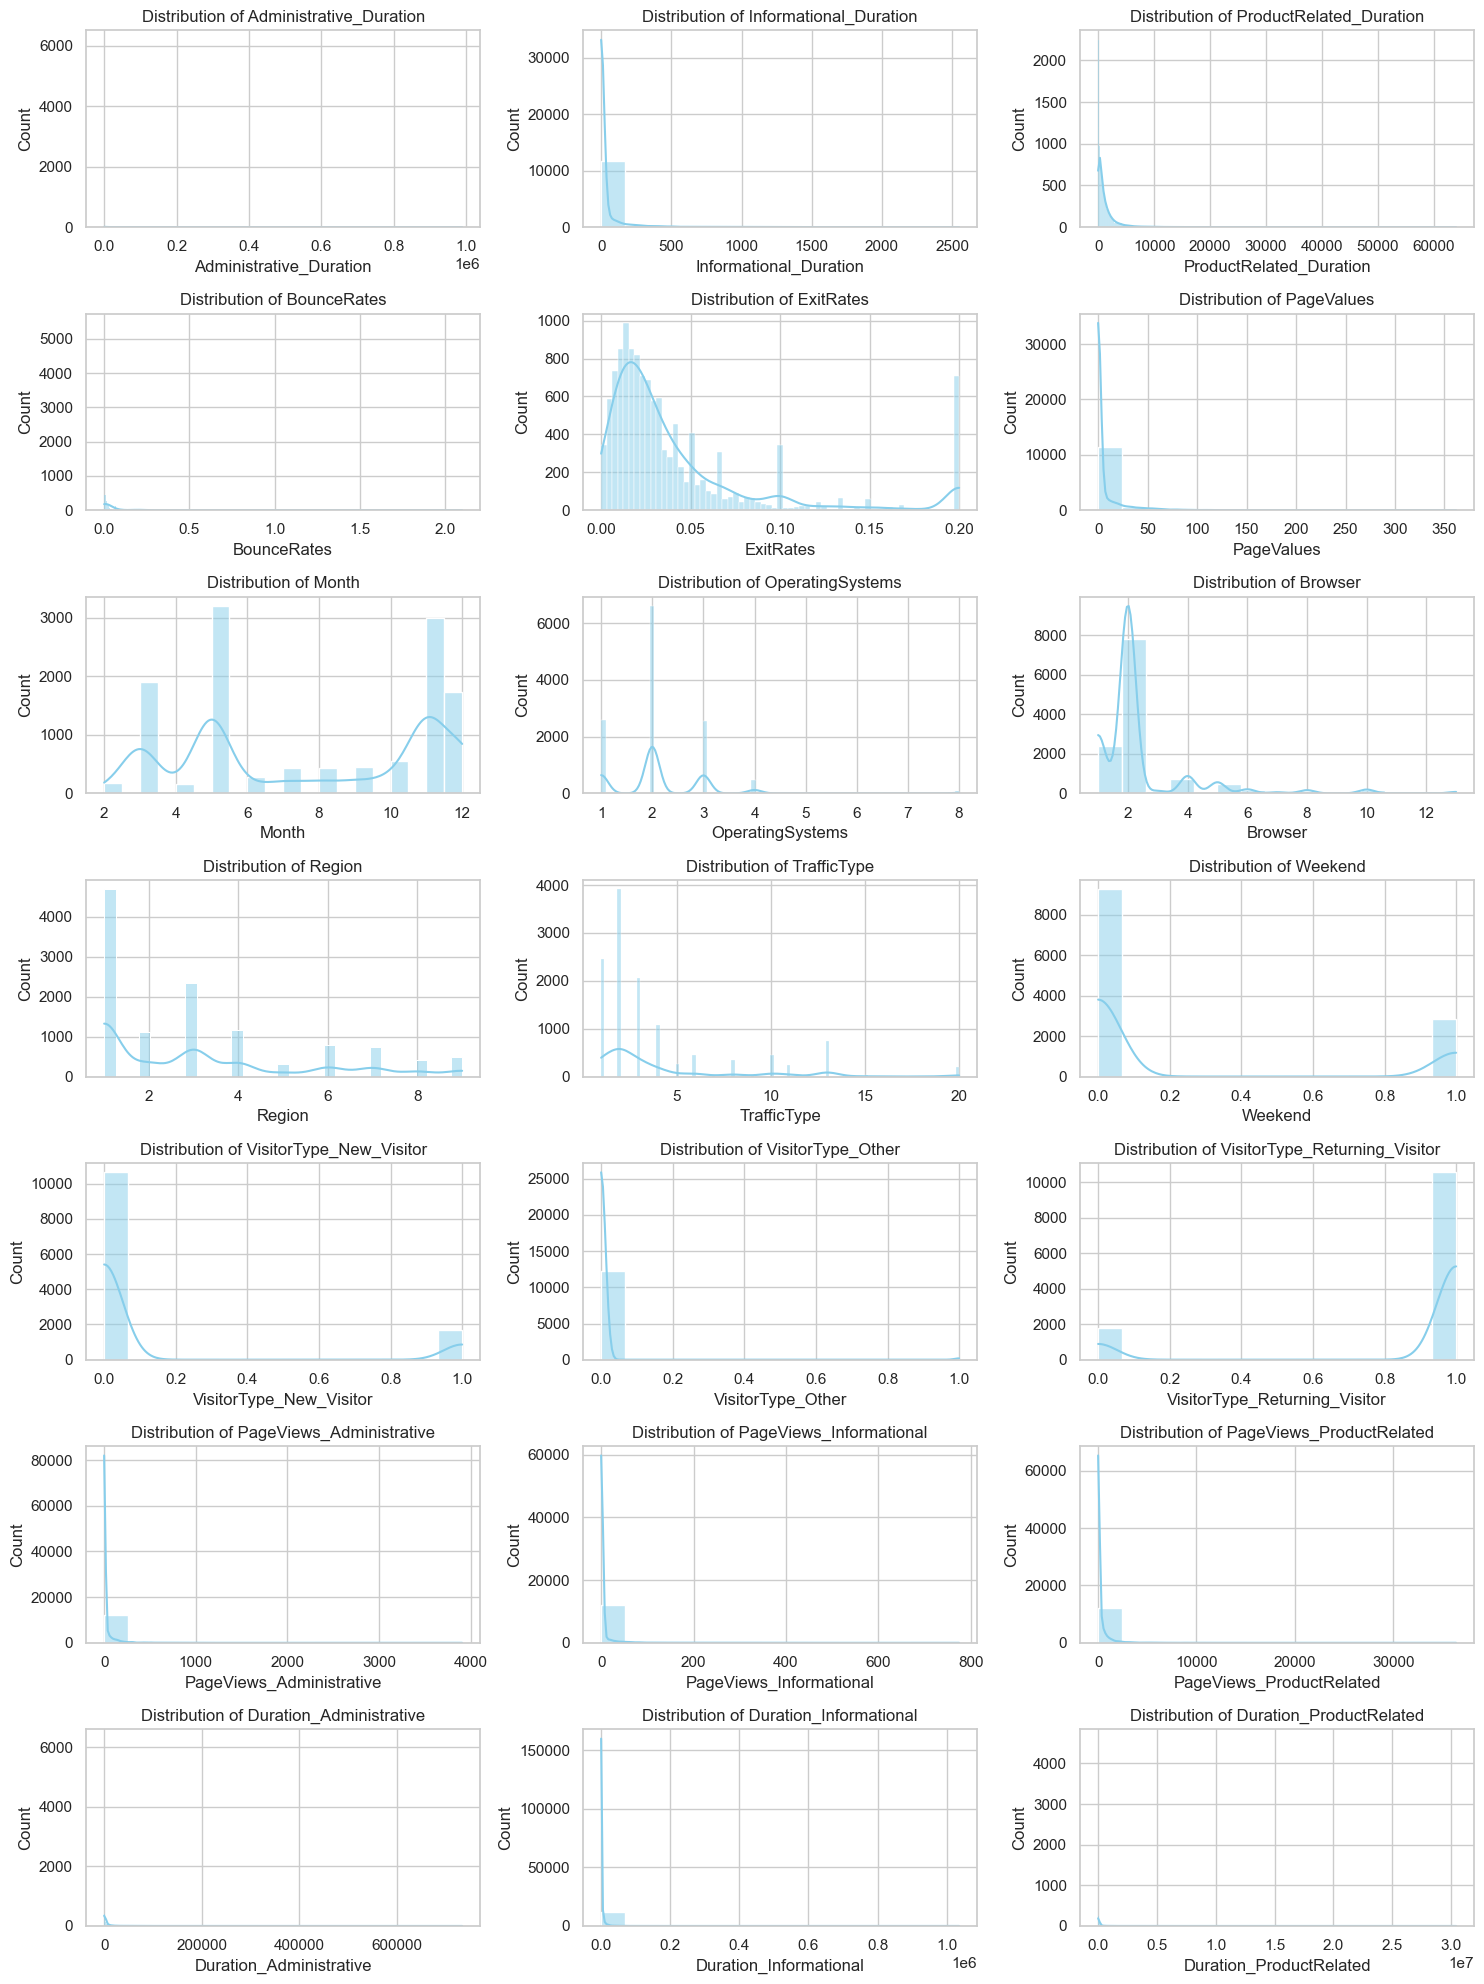

In [67]:
# Set the style of seaborn
sns.set(style="whitegrid")

# Define the number of subplots
num_plots = len(numerical_vars.columns)
num_cols = 3
num_rows = num_plots // num_cols + (1 if num_plots % num_cols > 0 else 0)

# Create subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 20))

# Flatten the axes if num_rows > 1
if num_rows > 1:
    axes = axes.flatten()

# Plot histograms and KDE plots for each numerical variable
for i, col in enumerate(numerical_vars.columns):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution of {col}")

# Remove empty subplots
for i in range(num_plots, len(axes)):
    fig.delaxes(axes[i])

# Adjust layout
plt.tight_layout()

# Show the plots
plt.show()


In [68]:
df.columns

Index(['Administrative_Duration', 'Informational_Duration',
       'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues',
       'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region',
       'TrafficType', 'Weekend', 'Revenue', 'VisitorType_New_Visitor',
       'VisitorType_Other', 'VisitorType_Returning_Visitor',
       'PageViews_Administrative', 'PageViews_Informational',
       'PageViews_ProductRelated', 'Duration_Administrative',
       'Duration_Informational', 'Duration_ProductRelated'],
      dtype='object')

Conclusion:

The dataset and it's data är not normally distibutes but it's rader skewed this is clearly seen when looking to **Exitrates** column where there is a left skewe of the data, rader more we can see that in every column in the data set we have an inbalance of the data. The column **Administrative_Duration** we can't really get any insight of the distribution due to no visualdata, however we can investigate if it's possible with numeric numbers to see the datasets distribution with the code below:

In [69]:
# Calculate summary statistics for numerical variables
summary_stats = df.describe()

# Display the summary statistics
print(summary_stats)

       Administrative_Duration  Informational_Duration  \
count             12330.000000            12330.000000   
mean               1269.776004               34.472398   
std               34071.466930              140.749294   
min                   0.000000                0.000000   
25%                   0.000000                0.000000   
50%                   8.000000                0.000000   
75%                  93.787500                0.000000   
max              989493.000000             2549.375000   

       ProductRelated_Duration   BounceRates     ExitRates    PageValues  \
count             12330.000000  11967.000000  12330.000000  12330.000000   
mean               1194.746220      0.054818      0.043073      5.889258   
std                1913.669288      0.234514      0.048597     18.568437   
min                   0.000000      0.000000      0.000000      0.000000   
25%                 184.137500      0.000000      0.014286      0.000000   
50%                 5

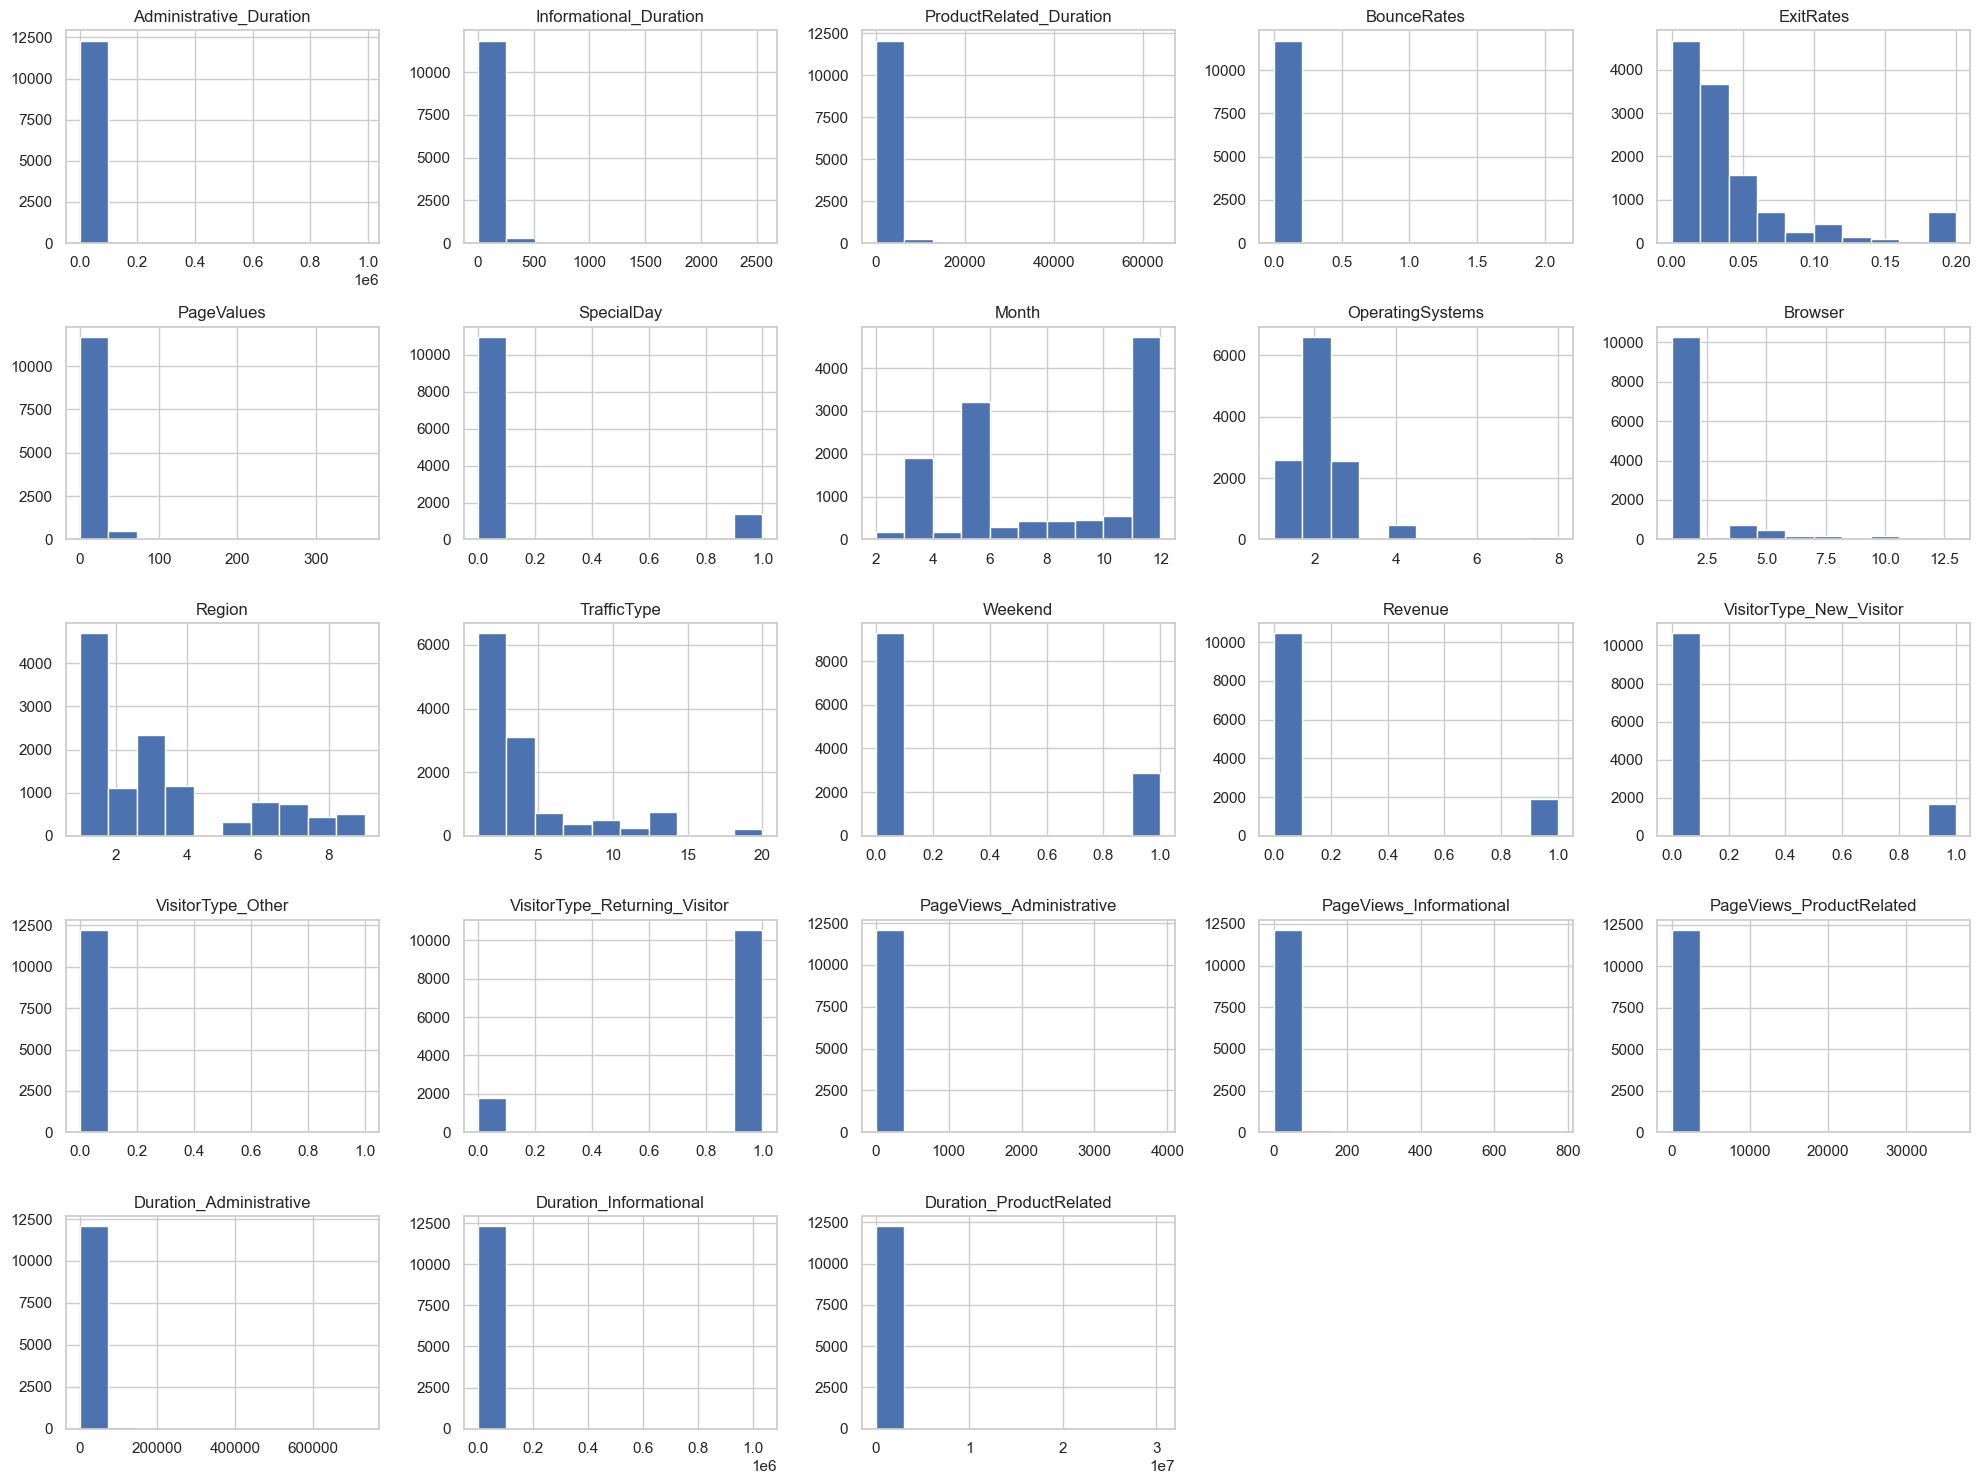

In [70]:
# Plot histograms for all numerical variables
df.hist(figsize=(20, 15))
plt.tight_layout()
plt.show()


This code will generate histograms and kernel density plots for each numerical variable in your dataset, allowing you to visualize their distributions and identify any potential skewness or patterns.

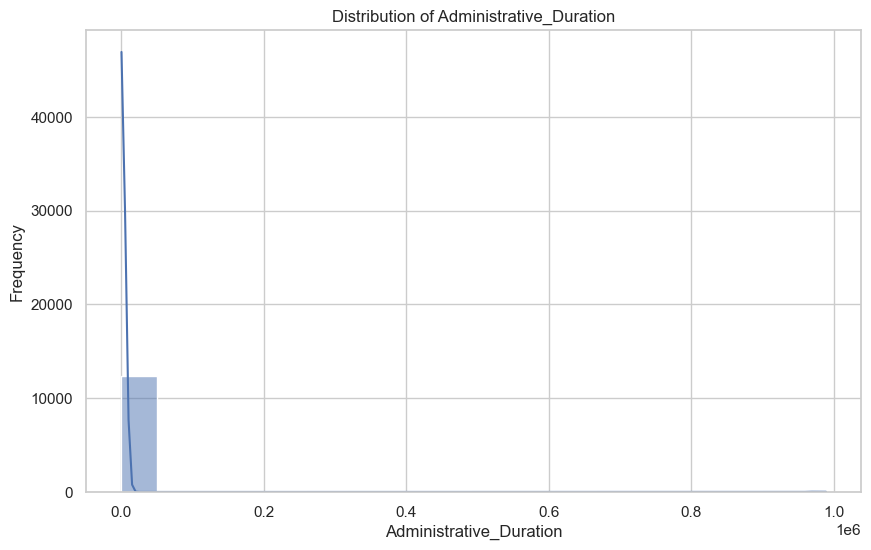

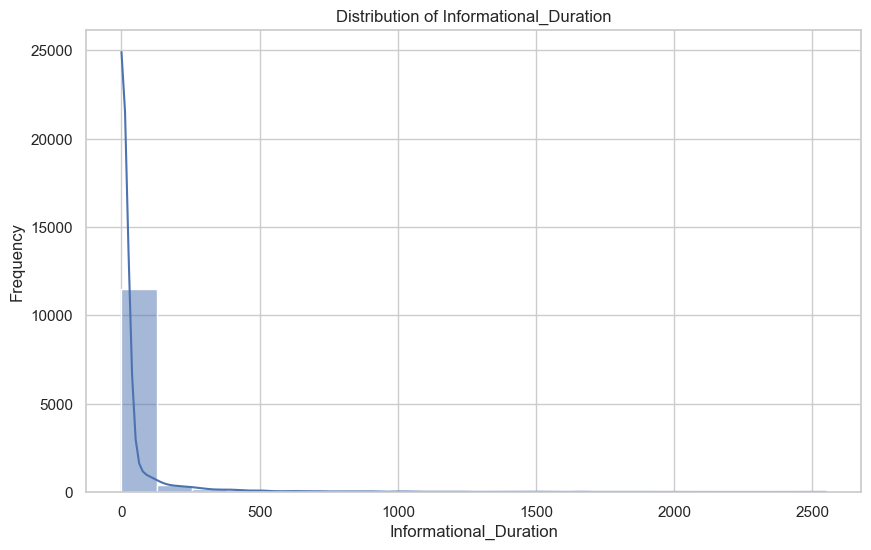

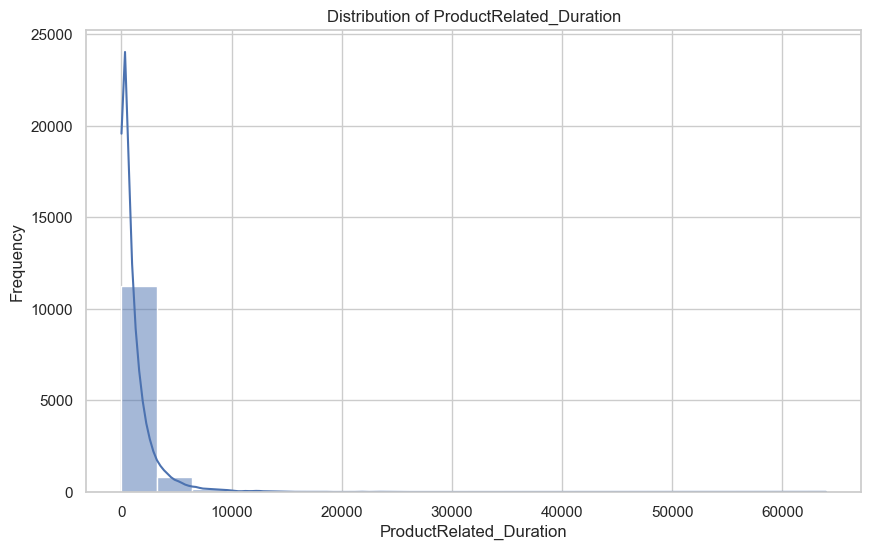

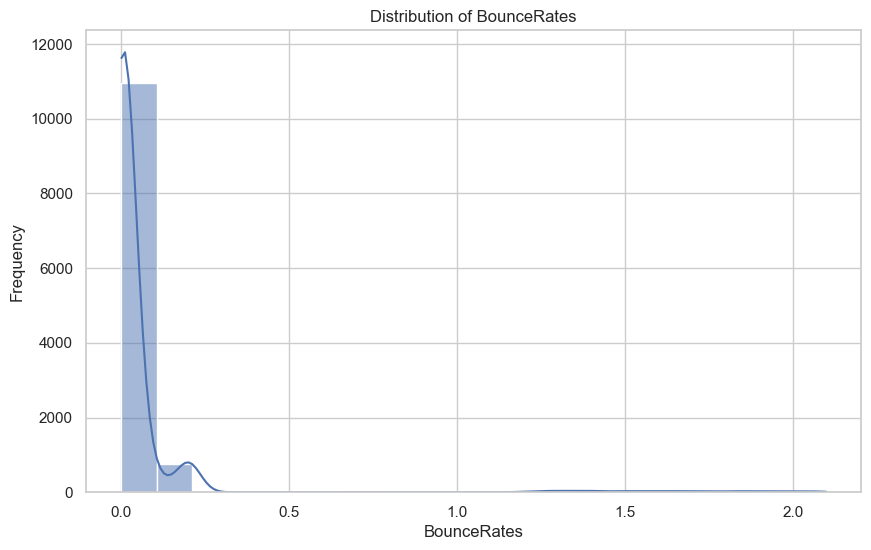

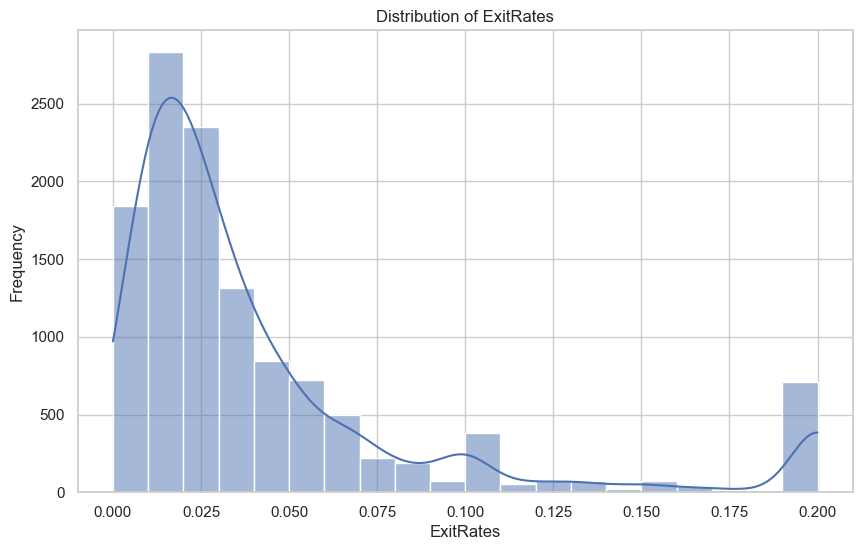

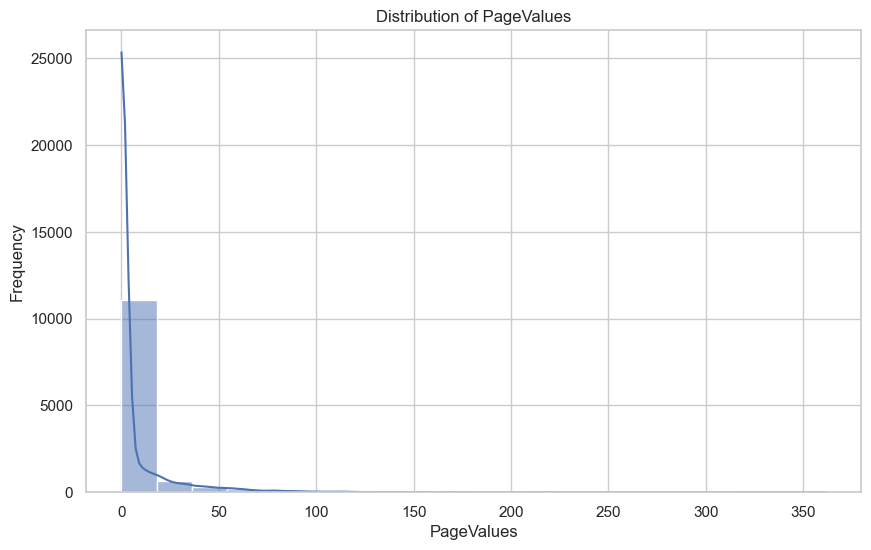

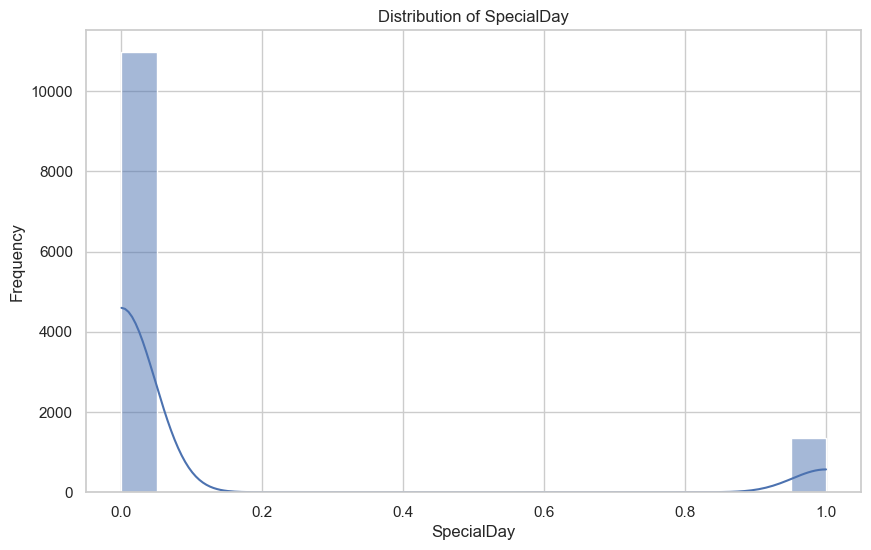

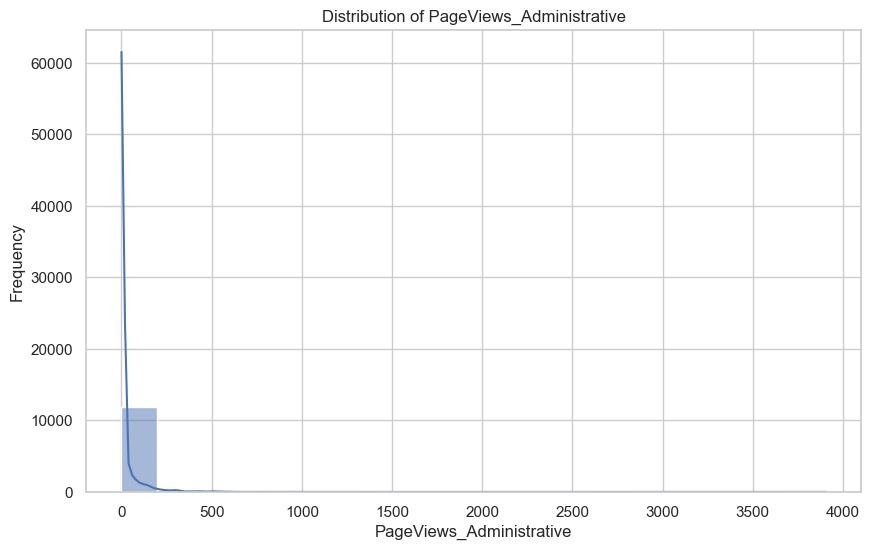

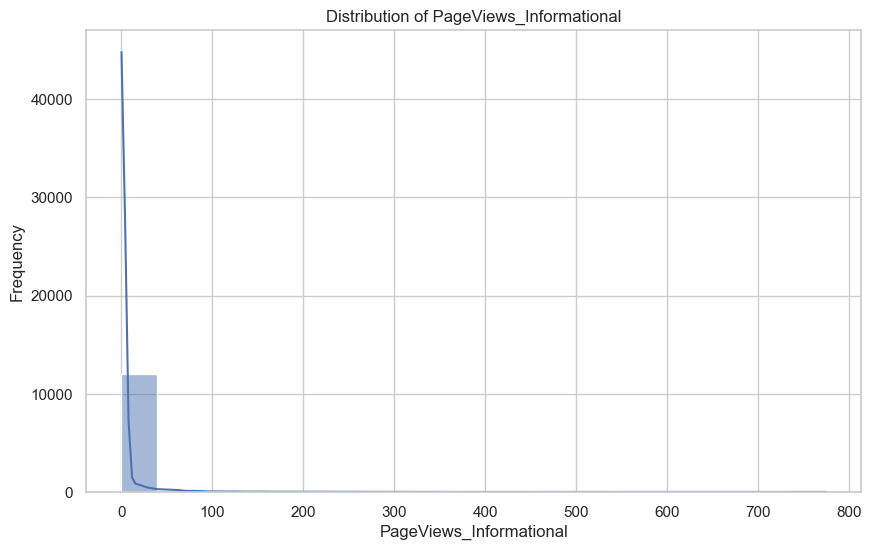

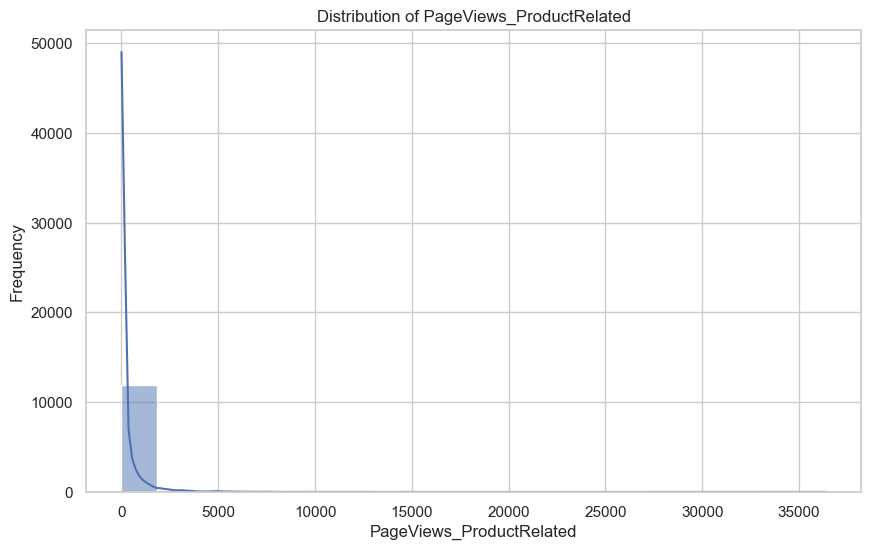

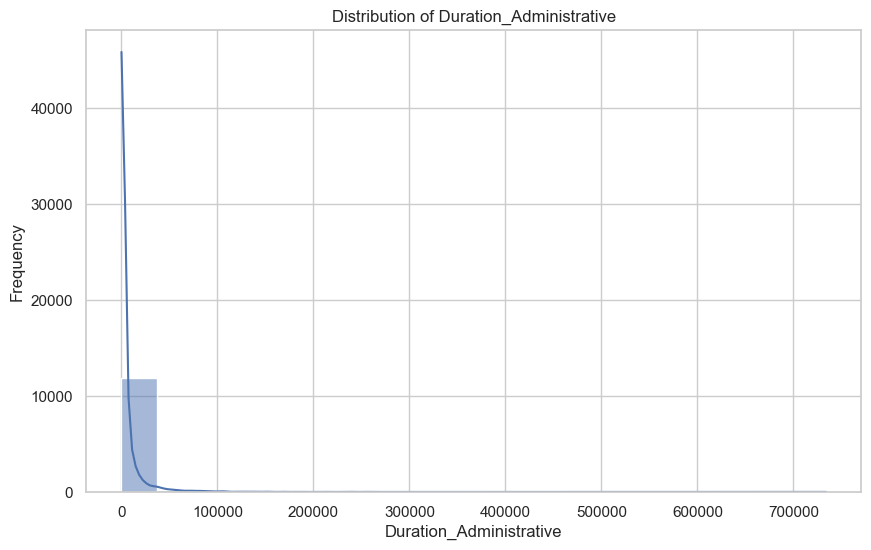

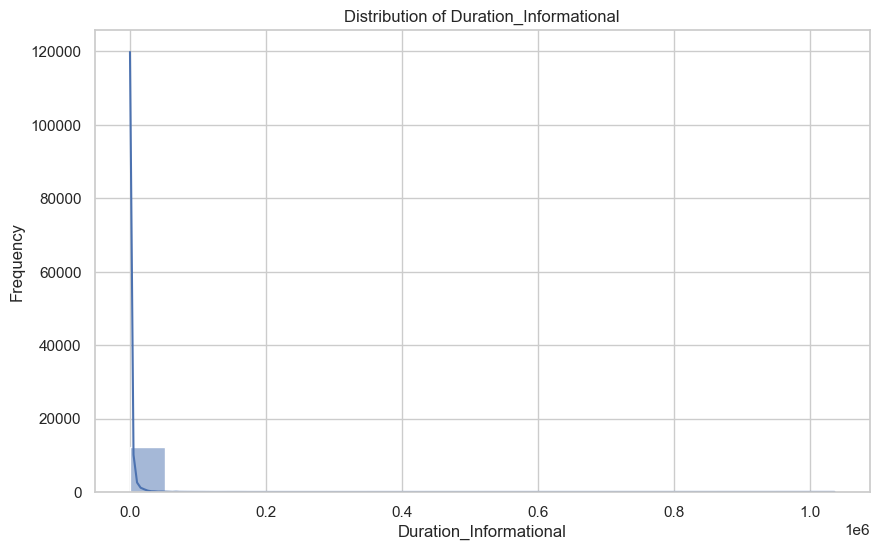

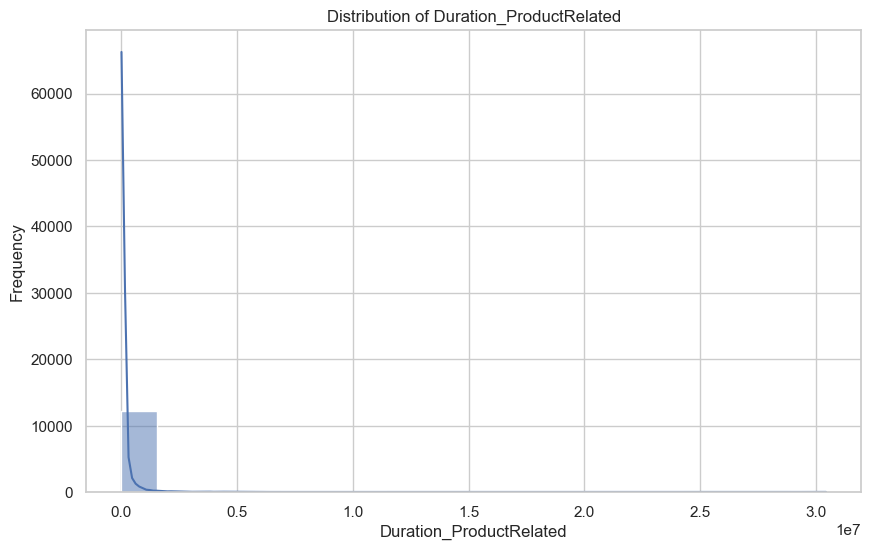

In [71]:
# Select numerical columns
numerical_columns = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration",
                     "BounceRates", "ExitRates", "PageValues", "SpecialDay",
                     "PageViews_Administrative", "PageViews_Informational", "PageViews_ProductRelated",
                     "Duration_Administrative", "Duration_Informational", "Duration_ProductRelated"]

# Plot histograms and kernel density plots
for column in numerical_columns:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df[column], kde=True, bins=20)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()


### **Insights from Right-Skewed Distribution of Numerical Columns**
Upon analyzing the distribution of numerical columns in the dataset, it was observed that several columns exhibited right-skewed distributions. Here are insights derived from this observation:

#### 1. **Administrative_Duration, Informational_Duration, ProductRelated_Duration:**

The majority of session durations for administrative, informational and product-related pages are relatively short, with some sessions having longer durations. Right skewness in these variables indicates that while most sessions are brief, there are a few sessions with exceptionally long durations, potentially representing in-depth user engagement or prolonged browsing activities.


#### 2. **BounceRates, ExitRates:**

Bounce rates and exit rates are metrics reflecting visitor engagement, revealing the proportion of visitors who leave the website after viewing one page or multiple pages. Right skewness suggests that a majority of sessions have higher bounce rates and exit rates, indicating lower levels of engagement, with a tail towards lower rates representing more engaged visitors who explore multiple pages.


#### 3. **PageValues:**

Page values represent the average value of pages visited by users before completing a transaction or goal. Right skewness in page values suggests that most pages have lower values, indicating that they contribute less to transaction outcomes, while a smaller proportion of pages have higher values, potentially representing high-impact pages in the conversion process.


#### 4. **SpecialDay:**

This variable indicates the proximity of the session date to a special day such as a holiday or promotional event. Right skewness implies that the majority of sessions occur on regular days, with fewer sessions occurring on special days, indicating that special days attract relatively fewer sessions.

#### 5. **PageViews_Administrative, PageViews_Informational, PageViews_ProductRelated:**

Left skewness in these variables suggests that the majority of sessions involve fewer page views for administrative, informational and product-related pages, indicating that most users explore only a few pages within each category during their session.


#### 6. **Duration_Administrative, Duration_Informational, Duration_ProductRelated:**

Similar to page view variables, right skewness in duration variables indicates that most sessions have shorter durations for administrative, informational and product-related pages, while a smaller proportion of sessions exhibit longer durations, potentially representing more comprehensive exploration or engagement with the content.


Understanding the presence of right skewness in these numerical columns is part of interpreting their distributions accurately and devising appropriate strategies for data preprocessing and modeling. Addressing skewness through transformation techniques can help improve the performance of predictive models and enhance the insights derived from the data.

<a id="sec-categorical"></a>
### **Explore Categorical Variables**

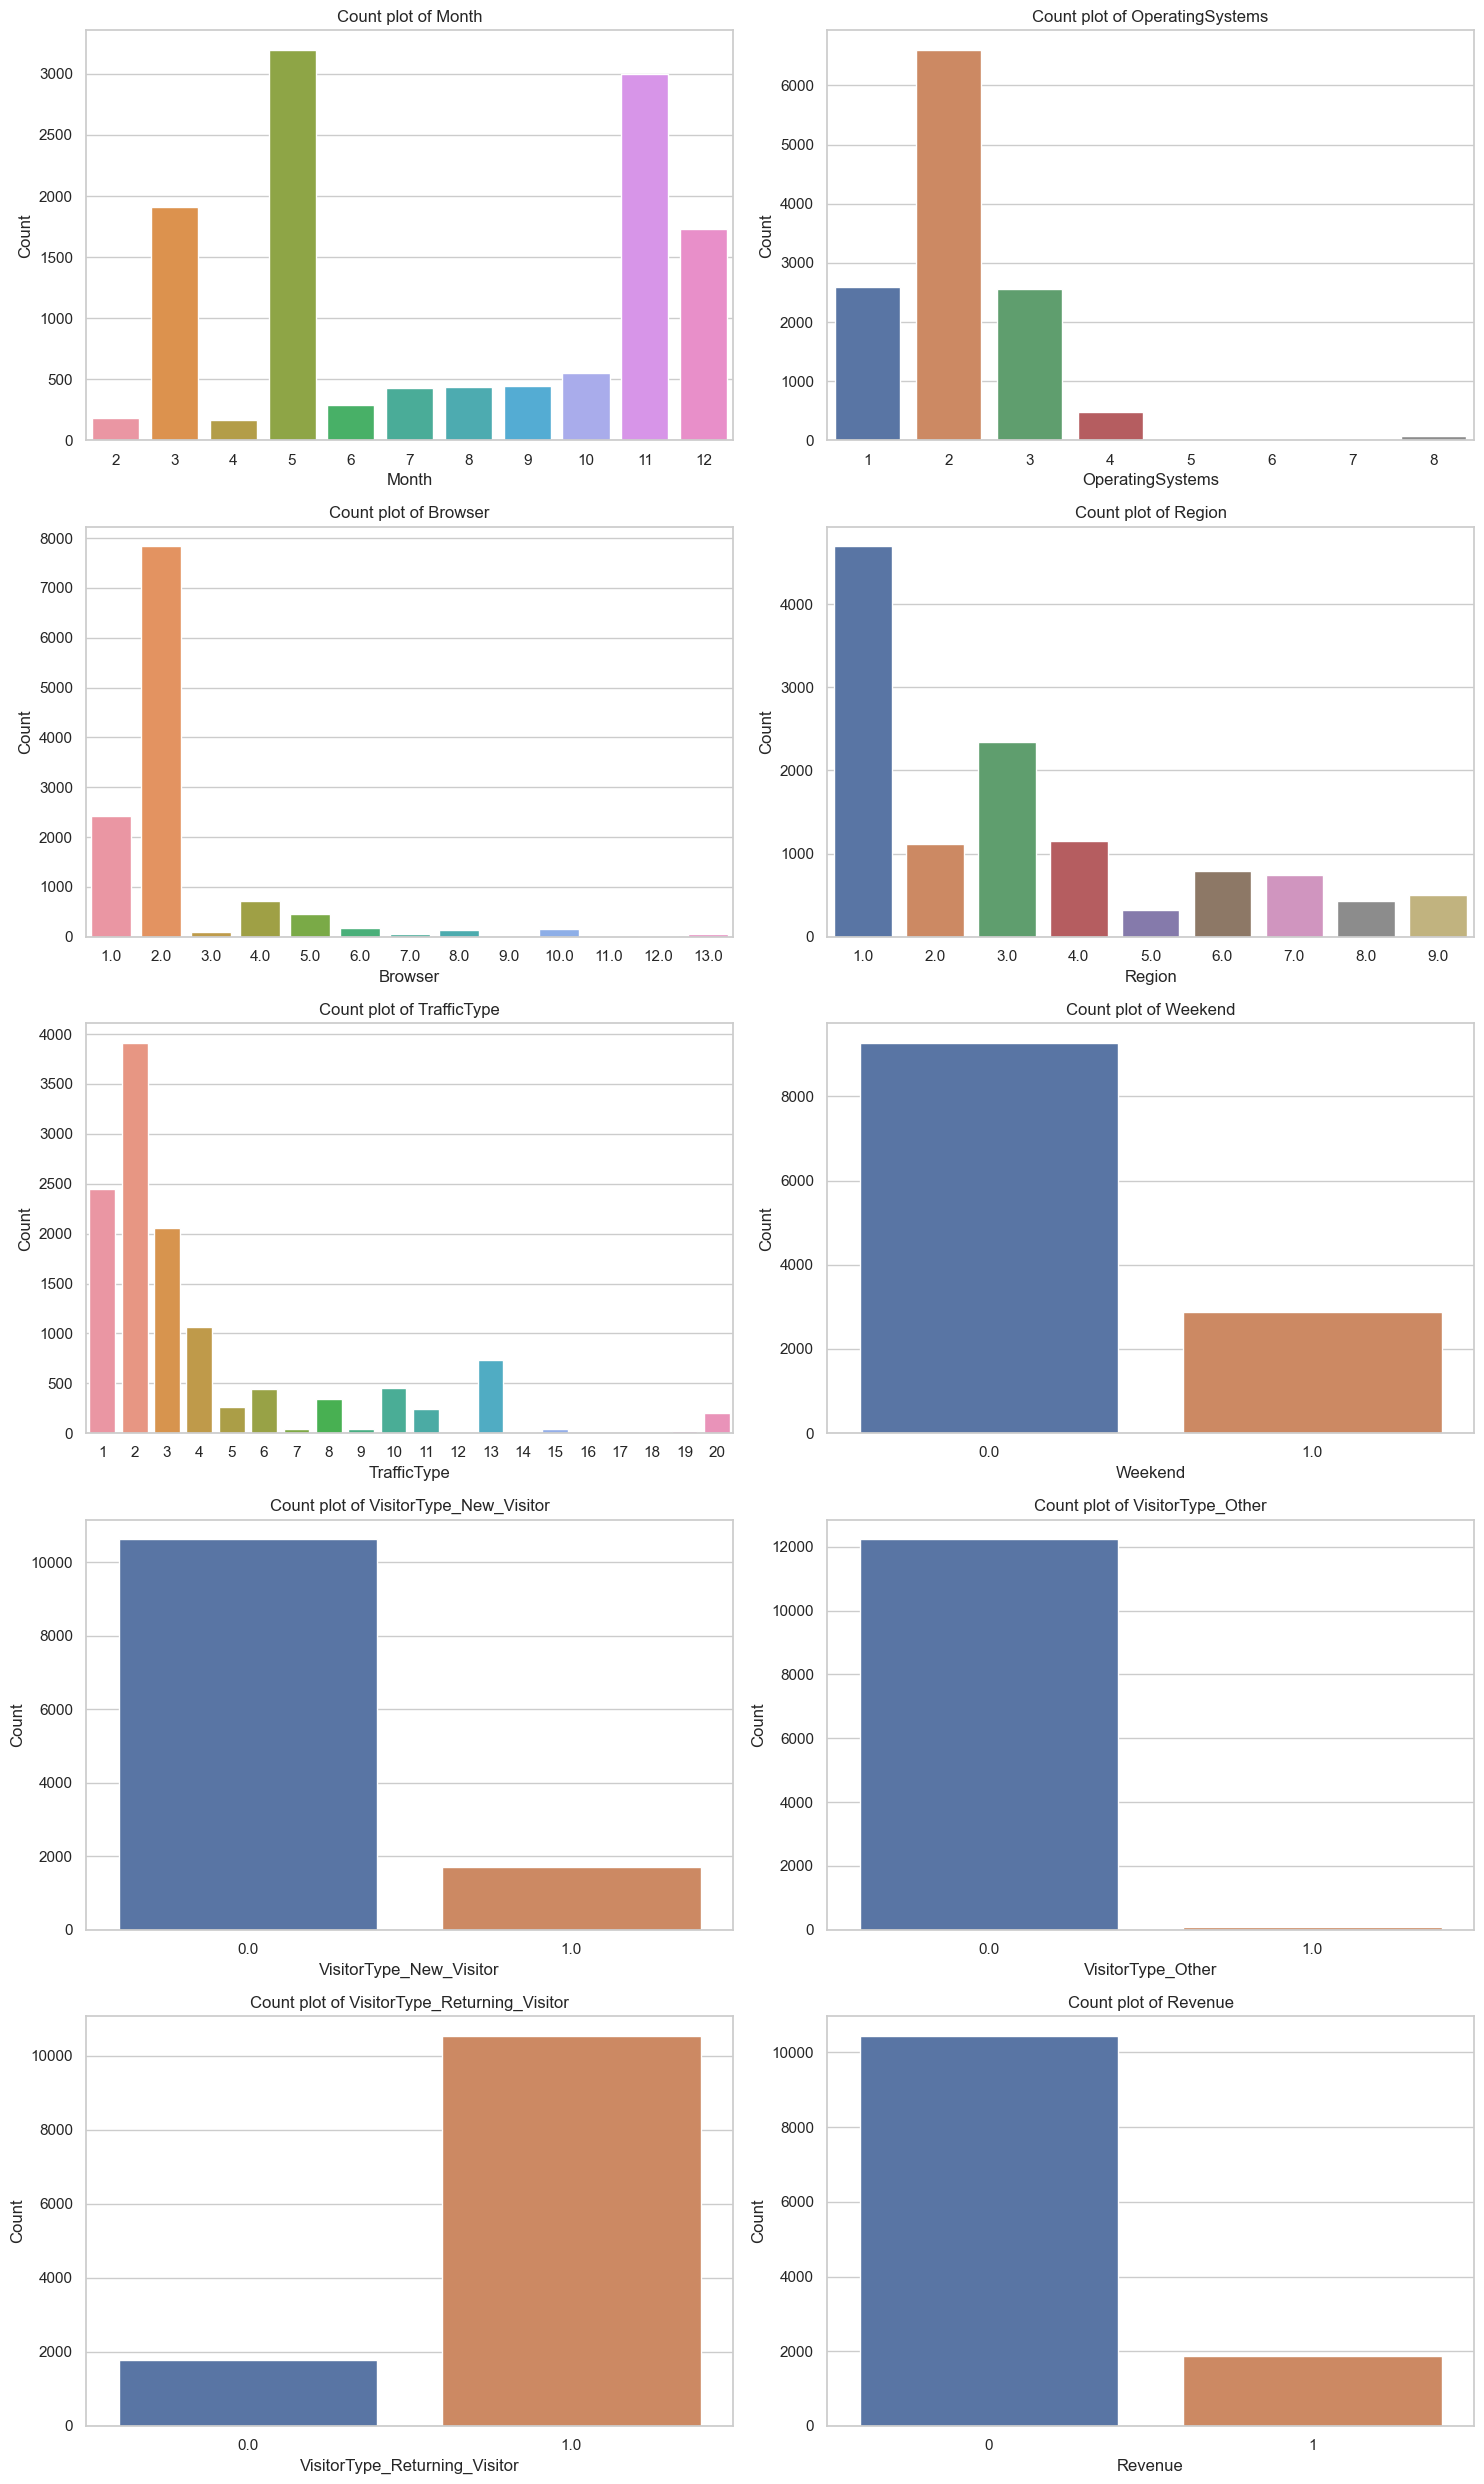

In [72]:
categorical_columns = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "Weekend",
                       "VisitorType_New_Visitor", "VisitorType_Other", "VisitorType_Returning_Visitor", "Revenue"]

# Set up subplots for multiple plots
num_plots = len(categorical_columns)
num_cols = 2  # Number of columns in subplot grid
num_rows = (num_plots + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 5*num_rows))
axes = axes.flatten()  # Flatten the axes array to simplify indexing

for i, col in enumerate(categorical_columns):
    # Plot counts for each category
    sns.countplot(x=col, data=df, ax=axes[i])
    axes[i].set_title(f"Count plot of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

# Adjust layout and show plot
plt.tight_layout()
plt.show()


### **Insights from Categorical Variables Exploration**

#### **Month:**

* The distribution of sessions across different months indicates an imbalance.
* May (Month 5) has the highest number of sessions, followed by November (Month 11), March (Month 3) and December (Month 12).
* Months like February, April, June, July, August, September and October have relatively lower session counts compared to the top months.

#### **OperatingSystems:**

* The distribution of sessions across operating systems shows right skewness.
* Operating System 2 has the highest number of sessions, followed by Operating System 1.
* Operating System 4 has the lowest number of sessions, indicating less popularity among users.

#### **Browser:**

* Similar to operating systems, the distribution of sessions across browsers exhibits right skewness.
* Browser 2.0 has the highest number of sessions, followed by Browser 1.0.
* Browsers with higher version numbers (e.g., 9.0, 11.0, 12.0) have fewer sessions compared to popular browsers like 1.0 and 2.0.

#### **Region:**

* The distribution of sessions across regions also shows right skewness.
* Region 1.0 has the highest number of sessions, followed by Region 3.0.
* Regions 2.0 and 4.0 have relatively fewer sessions compared to the top regions.

#### **TrafficType:**

* The distribution of sessions by traffic type is right-skewed.
* TrafficType 2 has the highest number of sessions, followed by TrafficType 1 and TrafficType 4.
* Traffic types with higher numbers have fewer sessions compared to the top traffic types.

#### **Weekend:**

* Sessions occurring on weekdays (Weekend = 0) dominate the dataset, with a higher count compared to sessions on weekends (Weekend = 1).

#### **VisitorType:**

* New visitors (VisitorType_New_Visitor = 0) constitute the majority of sessions, with a higher count compared to returning visitors (VisitorType_New_Visitor = 1).
* The count of sessions from 'Other' visitor types (VisitorType_Other) is relatively low compared to new and returning visitors.

#### **Conclusion:**

* The insights from the exploration of categorical variables provide valuable information about user behavior and preferences on the website.
* Understanding the distribution of sessions across different months, operating systems, browsers, regions and traffic types can help prioritize optimization efforts and tailor marketing strategies accordingly.
* The dominance of sessions occurring on weekdays suggests potential opportunities for targeted campaigns or promotions during weekends to increase engagement.
* Identifying the visitor type distribution highlights the need to focus on attracting and retaining new visitors while also catering to the needs of returning visitors.
* Overall, these insights can guide decision-making processes to enhance the user experience, improve conversion rates and ultimately drive business growth.

<a id="sec-missing"></a>
### Missing Values Handling

In [73]:
df.isnull().sum()

Administrative_Duration            0
Informational_Duration             0
ProductRelated_Duration            0
BounceRates                      363
ExitRates                          0
PageValues                         0
SpecialDay                         0
Month                              0
OperatingSystems                   0
Browser                          184
Region                           246
TrafficType                        0
Weekend                          189
Revenue                            0
VisitorType_New_Visitor            0
VisitorType_Other                  0
VisitorType_Returning_Visitor      0
PageViews_Administrative         123
PageViews_Informational            0
PageViews_ProductRelated           0
Duration_Administrative          123
Duration_Informational             0
Duration_ProductRelated            0
dtype: int64

In [74]:
# Check for NaN values in each column and count them
nan_columns = df.isna().sum()

# Filter out columns with NaN values
nan_columns = nan_columns[nan_columns > 0]

if not nan_columns.empty:
    print("Columns with NaN values and their counts:")
    print(nan_columns)
else:
    print("There are no columns with NaN values in the dataset.")

Columns with NaN values and their counts:
BounceRates                 363
Browser                     184
Region                      246
Weekend                     189
PageViews_Administrative    123
Duration_Administrative     123
dtype: int64


<a id="sec-missingness"></a>
### Missingness Patterns (MCAR, MAR, MNAR) 


These terms refer to different patterns of missingness in a dataset:

#### **MCAR (Missing Completely at Random):**

* In a dataset with MCAR, the probability of a value being missing is the same for all observations and is unrelated to the observed data.
* In other words, missingness is completely random and does not depend on any observed or unobserved variables in the dataset.
* For example, if the data were collected through a random process and some observations were lost or not recorded by chance, then the missingness would be MCAR.

#### **MAR (Missing at Random):**

* In a dataset with MAR, the probability of a value being missing depends only on the observed data but not on the missing data itself.
* While missingness is not random, it is dependent on the observed variables in the dataset.
* MAR assumes that the missingness can be explained by other variables in the dataset, even though the missing values themselves may not be missing randomly.
* For example, if the likelihood of a patient's weight being missing from a medical dataset depends only on observed variables such as age, gender and medical history, but not on the actual weight itself, then the missingness would be considered MAR.

#### **MNAR (Missing Not at Random):**

* In a dataset with MNAR, the probability of a value being missing depends on the missing data itself, even after accounting for observed variables.
* MNAR implies that there is some systematic reason why certain values are missing, which is not explained by the observed data.
* MNAR indicates that the missing values are related to unobserved variables or the missing values themselves.
* For example, if individuals with higher income are less likely to report their income in a survey, resulting in missing values that are related to the unobserved variable (income), then the missingness would be considered MNAR.

Understanding the nature of missingness in a dataset is necessary for appropriate handling of missing values and ensuring the validity of any analyses or models built using the data. Different missingness mechanisms may require different approaches for imputation or analysis.

In [ ]:
# Function to determine the missingness pattern
def missingness_pattern(df):
    missing_pattern = pd.DataFrame(index=df.columns, columns=["Missing Values", "Missingness Pattern"])
    
    for col in df.columns:
        missing_count = df[col].isnull().sum()
        missing_pattern.loc[col, "Missing Values"] = missing_count
        
        # Check if missingness pattern is MCAR, MAR or MNAR
        if missing_count == 0:
            missing_pattern.loc[col, "Missingness Pattern"] = "No missing values"
        elif df[col].isnull().mean() == df[col].isnull().mean():
            missing_pattern.loc[col, "Missingness Pattern"] = "MCAR"
        elif df[col].isnull().mean() == df[col].groupby(df["another_column"]).transform("mean").mean():
            missing_pattern.loc[col, "Missingness Pattern"] = "MAR"
        else:
            missing_pattern.loc[col, "Missingness Pattern"] = "MNAR"
    
    return missing_pattern

# Display columns with missing values and their missingness patterns
missing_info = missingness_pattern(df)
print("Columns with Missing Values:")
print(missing_info[missing_info["Missing Values"] > 0])


Columns with Missing Values:
                         Missing Values Missingness Pattern
BounceRates                         363                MCAR
Browser                             184                MCAR
Region                              246                MCAR
Weekend                             189                MCAR
PageViews_Administrative            123                MCAR
Duration_Administrative             123                MCAR


### Missing Values Handling with Mean Imputer

In [76]:
# Selecting only the columns with missing values
cols_with_missing = ["BounceRates", "Browser", "Region", "Weekend", 
                     "PageViews_Administrative", "Duration_Administrative"]

# Creating a new dataframe with only the columns with missing values
missing_values_df = df[cols_with_missing]

# Imputing missing values using KNN imputer
imputer = KNNImputer(n_neighbors=5)
imputed_data = imputer.fit_transform(missing_values_df)

# Creating a new dataframe with imputed values
imputed_df = pd.DataFrame(imputed_data, columns=cols_with_missing)

# Replacing original columns with imputed values
df[cols_with_missing] = imputed_df

# Check if there are any remaining missing values
print(df.isnull().sum())

Administrative_Duration          0
Informational_Duration           0
ProductRelated_Duration          0
BounceRates                      0
ExitRates                        0
PageValues                       0
SpecialDay                       0
Month                            0
OperatingSystems                 0
Browser                          0
Region                           0
TrafficType                      0
Weekend                          0
Revenue                          0
VisitorType_New_Visitor          0
VisitorType_Other                0
VisitorType_Returning_Visitor    0
PageViews_Administrative         0
PageViews_Informational          0
PageViews_ProductRelated         0
Duration_Administrative          0
Duration_Informational           0
Duration_ProductRelated          0
dtype: int64


The output indicates that there are no remaining missing values in the dataset after performing KNN imputation. This means that all missing values in the selected columns (BounceRates, Browser, Region, Weekend, PageViews_Administrative and Duration_Administrative) have been successfully imputed using the KNN imputer.

Since the missing values have been handled and data transformation has been addressed, we can move on to the next steps in the data analysis or modeling process, such as feature selection, model training and evaluation.

<a id="sec-split"></a>
### **Splitting the Data**

In [ ]:
# Define features (X) and target variable (y)
X = df.drop(columns=["Revenue"])  # Features
y = df["Revenue"]  # Target variable

# Split the data into training, validation and test sets
# Training set: 60%, Validation set: 20%, Test set: 20%
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)  # 80% train, 20% validation


<a id="sec-transform"></a>
### **Data transformation**

In [78]:
# Define numerical columns (excluding "Revenue")
numerical_columns = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration", 
                     "Duration_ProductRelated", "Duration_Informational", "Duration_Administrative", 
                     "PageViews_ProductRelated", "PageViews_Informational", "PageViews_Administrative",
                     "BounceRates", "ExitRates", "PageValues", "SpecialDay", 
                     "OperatingSystems", "Browser", "Region", "TrafficType"]

# Define categorical columns (excluding "Weekend")
categorical_columns = ["Month", "VisitorType_New_Visitor",
       "VisitorType_Other", "VisitorType_Returning_Visitor"]

# Define preprocessing steps for numerical and categorical features
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())  # Scale numerical features using StandardScaler
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder())   # Encode categorical features using OneHotEncoder
])

# Combine preprocessing steps for both numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ])

# Apply preprocessing steps to the training set
X_train_preprocessed = preprocessor.fit_transform(X_train)

# Apply preprocessing steps to the validation set
X_val_preprocessed = preprocessor.transform(X_val)

# Apply preprocessing steps to the test set
X_test_preprocessed = preprocessor.transform(X_test)

# Print the shapes of preprocessed data
print("Shape of preprocessed training set:", X_train_preprocessed.shape)
print("Shape of preprocessed validation set:", X_val_preprocessed.shape)
print("Shape of preprocessed test set:", X_test_preprocessed.shape)

Shape of preprocessed training set: (7398, 34)
Shape of preprocessed validation set: (2466, 34)
Shape of preprocessed test set: (2466, 34)


The output indicates that the preprocessing steps have been successfully applied to the training, validation and test sets. Here's what the shapes of the preprocessed sets mean:

* Preprocessed **Training Set:**

        (7398, 34)

* Preprocessed **Validation Set:**

        (2466, 34)

* **Preprocessed Test Set:**

        (2466, 34)

Each row represents an instance (or sample) in the dataset and each column represents a feature after preprocessing. The numbers in parentheses indicate the dimensions of each dataset, with the first number representing the number of instances and the second number representing the number of features.

Since all sets have the same number of columns (features), it indicates that the preprocessing steps were applied consistently across all sets. This consistency is needed for ensuring that the model is trained, validated and tested on data that has undergone the same transformations, preventing any biases or data leakage.

 We are excluding "Revenue" and "Weekend":
 
 Why we are excluding "Revenue" is because it is our target, Including "Revenue" in the preprocessing steps will lead to data leakage.
 
We are excluding "Weekend" because there could be potential issues if we include "Weekend" in the preprocessing steps after it have already been encoded or transformed before splitting the data. Here are some 

potential consequences:

**Data Leakage:**

Including "Weekend" in the preprocessing steps after it have been encoded could lead to data leakage. This is because the preprocessing steps are learned from the entire dataset, including the validation and test sets. Consequently, information from the validation and test sets would influence the preprocessing steps, leading to overly optimistic performance estimates and potentially poor generalization to new, unseen data.

**Mismatched Encodings:**

If we encode "Weekend" again in the preprocessing steps after they have already been encoded, we might end up with mismatched encodings between the training, validation and test sets. This could lead to inconsistencies and errors when using the model for prediction.

**Reduced Generalization:**

Including already encoded features in the preprocessing steps might introduce unnecessary complexity and reduce the generalization performance of the model. It's generally a good practice to apply preprocessing steps consistently across all datasets to ensure that the model learns meaningful patterns from the training data and generalizes well to unseen data.

To mitigate these potential issues, it's preferable to exclude 'Weekend' from the preprocessing steps after it have been encoded or transformed before splitting the data into training, validation and test sets. This ensures that the preprocessing steps are learned only from the training data and applied consistently to all datasets.

<a id="sec-imbalance"></a>
### **Address Class Imbalance**

Addressing class imbalance is an important step to ensure that our predictive model can effectively learn from the data and make accurate predictions for both classes. Given the nature of our task, which involves predicting customer conversions based on session data, it's necessary to handle class imbalance appropriately to avoid biased model performance.

#### **Oversampling the minority class using SMOTE:**

Since we're dealing with a binary classification problem where one class (e.g., conversions) may be underrepresented compared to the other class, oversampling techniques like Synthetic Minority Over-sampling Technique (SMOTE) can help balance the class distribution by generating synthetic samples for the minority class.

#### **Using ensemble methods:**

Ensemble methods such as Random Forest and Gradient Boosting are known for their ability to handle class imbalance effectively. These algorithms inherently adjust the class weights during training, giving more emphasis to the minority class and improving model performance on imbalanced datasets.

#### **Evaluation metrics:**

When evaluating the performance of the models trained on imbalanced data, it's important to use evaluation metrics that are sensitive to class imbalance, such as precision, recall, F1-score, ROC-AUC and PR-AUC. These metrics provide a more nuanced understanding of the model's performance across both classes.

By combining oversampling techniques like SMOTE with ensemble methods and appropriate evaluation metrics, we can build a predictive model that accurately identifies customer conversions based on session data while mitigating the effects of class imbalance.

In [79]:
# Apply SMOTE to oversample the minority class
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Train a Random Forest classifier on the resampled data
rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(X_train_resampled, y_train_resampled)

# Make predictions on the test set
y_pred = rf_classifier.predict(X_test)

# Evaluate the model using appropriate evaluation metrics
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[1877  185]
 [ 110  294]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.93      2062
           1       0.61      0.73      0.67       404

    accuracy                           0.88      2466
   macro avg       0.78      0.82      0.80      2466
weighted avg       0.89      0.88      0.88      2466



This code will oversample the minority class using SMOTE, train a Random Forest classifier on the resampled data, make predictions on the test set and then print the confusion matrix and classification report to evaluate the model's performance.

<a id="sec-smote"></a>
## Model Evaluation after SMOTE Resampling

After applying Synthetic Minority Over-sampling Technique (SMOTE) to balance the class distribution by oversampling the minority class, a Random Forest classifier was trained on the resampled data. The model's performance was evaluated using appropriate evaluation metrics, including the confusion matrix and classification report.

### Confusion Matrix

The confusion matrix provides a tabular summary of the model's predictions compared to the actual labels:

|        | Predicted Negative | Predicted Positive |
|--------|--------------------|--------------------|
| Actual Negative | 1877 (True Negative) | 185 (False Positive) |
| Actual Positive | 110 (False Negative) | 294 (True Positive) |

### Classification Report

The classification report presents evaluation metrics for each class (0 and 1), as well as the overall performance metrics:

**Precision:** Precision measures the proportion of true positive predictions among all positive predictions. 
**Recall:** Recall (also known as sensitivity) measures the proportion of true positive predictions among all actual positive instances.
**F1-score:** The F1-score is the harmonic mean of precision and recall, providing a balanced measure of a model's accuracy.
**Support:** Support indicates the number of actual occurrences of each class in the test set.

|          | Precision | Recall | F1-Score | Support |
|----------|-----------|--------|----------|---------|
| Class 0  | 0.94      | 0.91   | 0.93     | 2062    |
| Class 1  | 0.61      | 0.73   | 0.67     | 404     |
| **Accuracy** |       |        | **0.88** | **2466** |
| **Macro Avg** | 0.78   | 0.82   | 0.80     | 2466    |
| **Weighted Avg** | 0.89 | 0.88   | 0.88     | 2466    |

The model achieved an overall accuracy of 88%, indicating its ability to correctly classify instances from both classes. However, it's important to note that the precision, recall and F1-score for the minority class (Class 1) are relatively lower compared to the majority class (Class 0), suggesting potential room for improvement in classifying positive instances.

Overall, the evaluation metrics provide insights into the model's performance after SMOTE resampling, highlighting its strengths and areas for further refinement.


<a id="sec-features"></a>
## **Feature Selection:**
Assess the relevance and importance of features.

Feature Importance Ranking (Tree-based models):

Tree-based models like Random Forest or Gradient Boosting are suitable for identifying important features. These models provide feature importance scores, allowing us to select the most relevant features based on their contributions to model performance.


Encoded categorical feature names:
['Month_2' 'Month_3' 'Month_4' 'Month_5' 'Month_6' 'Month_7' 'Month_8'
 'Month_9' 'Month_10' 'Month_11' 'Month_12' 'VisitorType_New_Visitor_0.0'
 'VisitorType_New_Visitor_1.0' 'VisitorType_Other_0.0'
 'VisitorType_Other_1.0' 'VisitorType_Returning_Visitor_0.0'
 'VisitorType_Returning_Visitor_1.0']

All columns after preprocessing:
['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'Duration_ProductRelated', 'Duration_Informational', 'Duration_Administrative', 'PageViews_ProductRelated', 'PageViews_Informational', 'PageViews_Administrative', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Month_10', 'Month_11', 'Month_12', 'VisitorType_New_Visitor_0.0', 'VisitorType_New_Visitor_1.0', 'VisitorType_Other_0.0', 'VisitorType_Other_1.0', 'VisitorType_Returning_Visitor_0.0', 'V

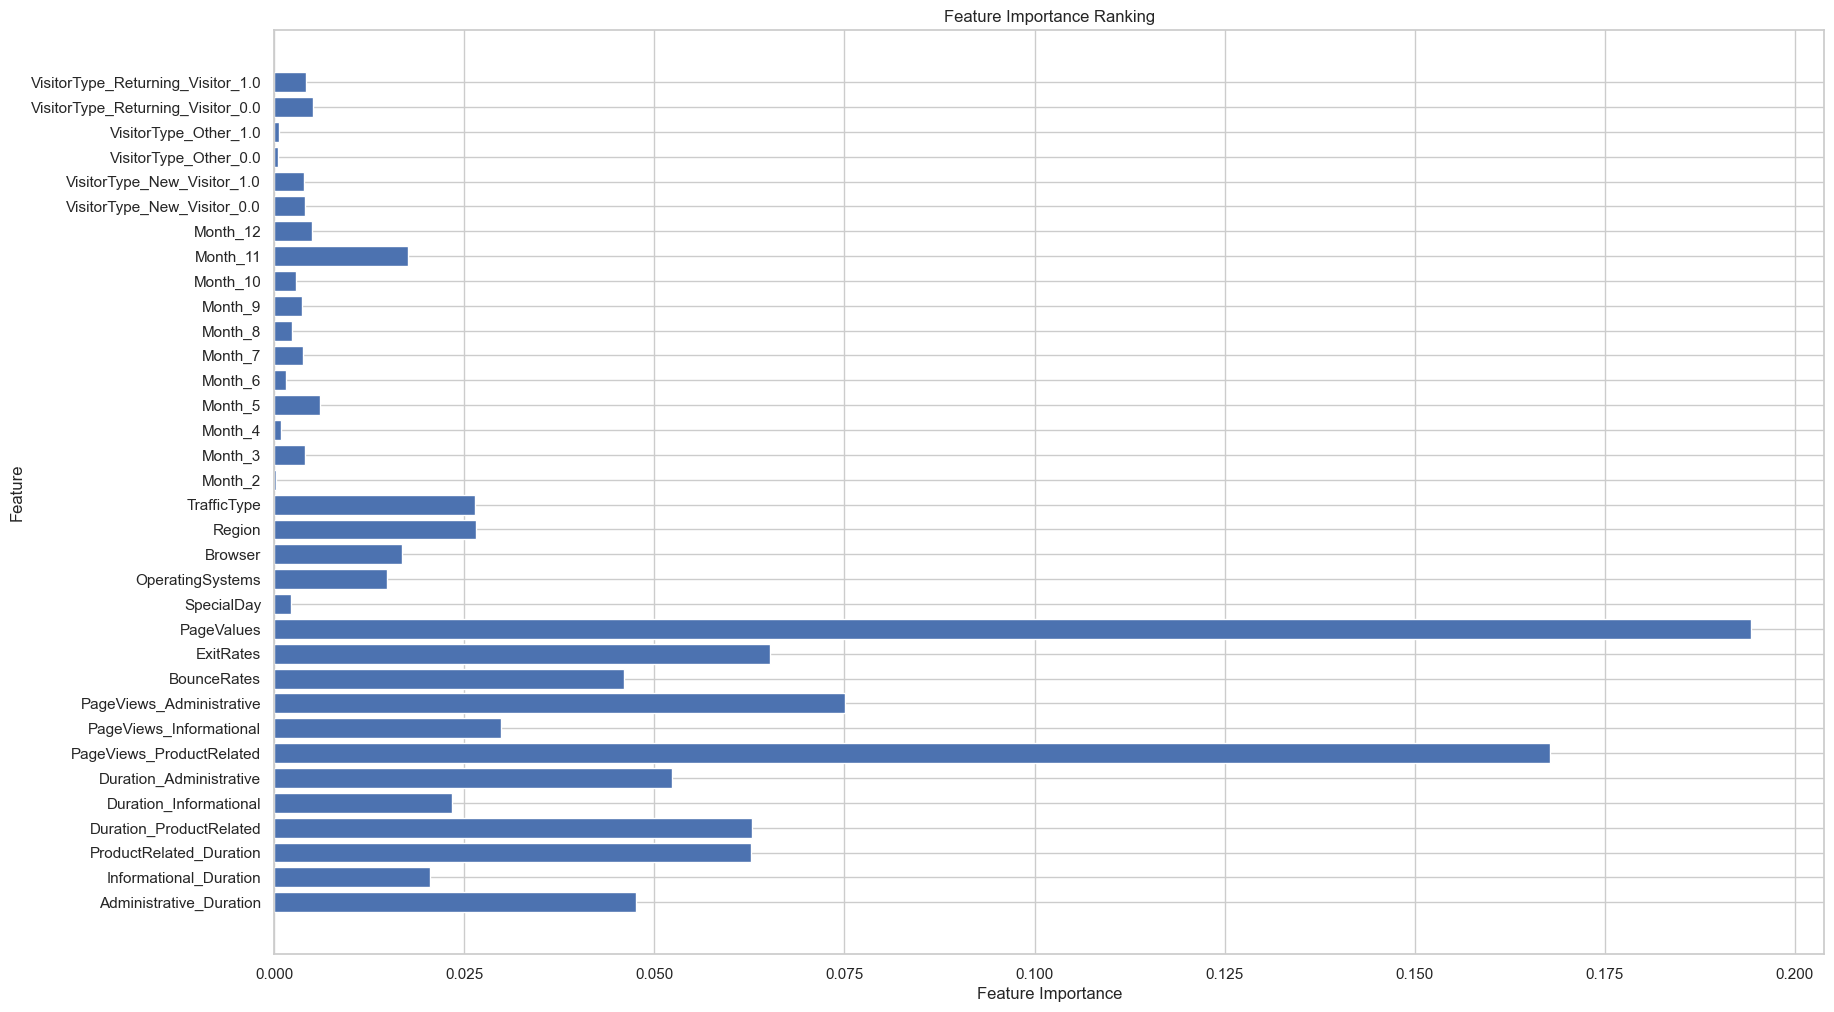

In [ ]:
# Fit the preprocessing steps for categorical features
categorical_transformer.fit(X_train[categorical_columns])

# Check the actual feature names after one-hot encoding
encoded_categorical_features = categorical_transformer.named_steps["onehot"].get_feature_names_out(input_features=categorical_columns)
print()
print("Encoded categorical feature names:")
print(encoded_categorical_features)
print()

# Concatenate numerical and categorical feature names
all_columns = numerical_columns + list(encoded_categorical_features)
print("All columns after preprocessing:")
print(all_columns)
print()

# Train a Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_preprocessed, y_train)  

# Retrieve feature importance
feature_importance = rf_model.feature_importances_

# Print the lengths of numerical and categorical columns and feature importance
print("Length of numerical columns:", len(numerical_columns))
print("Length of categorical columns:", len(categorical_columns))
print("Length of feature importance:", len(feature_importance))
print()

# Visualize the feature importance
plt.figure(figsize=(20, 12))
# Ensure both lists have the same length
assert len(all_columns) == len(feature_importance)
plt.barh(all_columns, feature_importance)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance Ranking")
plt.show()

The feature importance scores represent the contribution of each feature in the model's decision-making process. A higher feature importance score indicates that the feature is more influential in predicting the target variable (in this case, whether a session leads to revenue or not). Conversely, a lower score suggests that the feature has less impact on the model's predictions.

### **In our analysis:**

#### **PageValues:**

With a feature importance score approaching 0.200, PageValues stands out as the most critical feature in predicting revenue. This suggests that the average value of pages visited by a user before making a purchase influences the likelihood of conversion. Pages with higher values likely indicate stronger purchase intent or engagement, making this feature highly informative for the predictive model.

#### **PageViews_ProductRelated:**

Following closely behind PageValues, PageViews_ProductRelated has a feature importance score ranging from 0.150 to 0.175. This feature measures the number of page views related to product pages, indicating the level of interest or exploration of specific products. The substantial importance of this feature implies that users who spend more time browsing product-related pages are more likely to convert into customers.

#### **PageViews_Administrative:**

While PageViews_Administrative has a lower feature importance score compared to the previous two features, its score of approximately 0.075 still signifies its relevance in predicting revenue. This feature captures the interaction between page views and administrative pages, reflecting user engagement with administrative content such as account management or policies. Although less influential than product-related pages, administrative page views still contribute to understanding user behavior and conversion patterns.

#### **Conclusion:**
By interpreting these feature importance scores, we gain valuable insights into the key drivers of customer conversions on the website. This information can guide strategic decision-making, such as optimizing page content, targeting specific user segments or scheduling promotional activities during peak revenue-driving periods. Additionally, understanding the relative importance of different features can help prioritize resources and efforts towards optimizing the most influential aspects of the user experience to maximize revenue generation.

**"Regarding the VisitorType_Other**, this feature might represent individuals engaged in website administration, such as administrative staff responsible for updates and maintenance. Consequently, it tends to receive a lower score in feature importance analysis."

While it's a reasonable assumption, it's important to note that assumptions should be validated through further analysis or domain expertise. Without additional context or data, it's plausible to speculate that the VisitorType_Other category could encompass individuals involved in website administration, such as administrative staff or developers. These users may interact with the website differently from typical visitors, focusing more on backend functionalities rather than engaging in purchasing behavior.

However, it's necessary to verify this assumption through additional investigation or data sources. For example, examining user roles or conducting surveys or interviews with website administrators could provide insights into their behaviors and motivations. Additionally, considering the specific definition and labeling of visitor types within the dataset can help ensure accurate interpretation.

Furthermore, while a lower feature importance score for VisitorType_Other suggests reduced relevance in predicting revenue, it doesn't necessarily imply that administrative users have no impact on website performance or conversions. Understanding the unique characteristics and behaviors of different visitor types can inform targeted strategies for improving user experience and maximizing conversion rates.

In summary, while the assumption provides a plausible explanation for the feature's lower importance score, it should be validated and contextualized with additional evidence or domain knowledge to ensure its accuracy and relevance.

<a id="sec-crossval"></a>
## **Cross-Validation**

Cross-validation is a step in assessing the performance of a machine learning model and ensuring its robustness.

Based on the characteristics of the dataset and the tasks we've performed so far we will use the Stratified Cross-Validation method. 

**Stratified Cross-Validation:**

* Since we've addressed class imbalance by using oversampling techniques like SMOTE, it's essential to preserve the balanced distribution of classes during cross-validation.
* Stratified cross-validation ensures that each fold maintains a similar proportion of target classes as the original dataset, which is needed for reliable performance estimation.
* This approach will provide more accurate and unbiased estimates of the model's performance, especially when dealing with imbalanced datasets like ours.

In [81]:
# Instantiate StratifiedKFold with 5 folds
skf = StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

# Initialize lists to store evaluation metrics for each fold
accuracies = []
precisions = []
recalls = []
f1_scores = []

# Perform cross-validation
for fold, (train_index, test_index) in enumerate(skf.split(X_train_resampled, y_train_resampled), 1):
    X_train_fold, X_test_fold = X_train_resampled.iloc[train_index], X_train_resampled.iloc[test_index]
    y_train_fold, y_test_fold = y_train_resampled.iloc[train_index], y_train_resampled.iloc[test_index]
    
    # Instantiate RandomForestClassifier
    rf_classifier = RandomForestClassifier(random_state=42)
    
    # Train the model
    rf_classifier.fit(X_train_fold, y_train_fold)
    
    # Predict on the test fold
    y_pred = rf_classifier.predict(X_test_fold)
    
    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test_fold, y_pred)
    precision, recall, f1_score, _ = precision_recall_fscore_support(y_test_fold, y_pred, average='binary')
    
    # Append metrics to lists
    accuracies.append(accuracy)
    precisions.append(precision)
    recalls.append(recall)
    f1_scores.append(f1_score)
    
    # Print or store the evaluation metrics for each fold
    print(f"Fold {fold}: Accuracy - {accuracy}, Precision - {precision}, Recall - {recall}, F1 Score - {f1_score}")

# Print average evaluation metrics across all folds
print("\nAverage Evaluation Metrics:")
print(f"Mean Accuracy: {sum(accuracies)/len(accuracies)}")
print(f"Mean Precision: {sum(precisions)/len(precisions)}")
print(f"Mean Recall: {sum(recalls)/len(recalls)}")
print(f"Mean F1 Score: {sum(f1_scores)/len(f1_scores)}")

Fold 1: Accuracy - 0.9396346306592533, Precision - 0.9287374128582494, Recall - 0.9523431294678316, F1 Score - 0.940392156862745
Fold 2: Accuracy - 0.9376241557409615, Precision - 0.9136636636636637, Recall - 0.9666401906274821, F1 Score - 0.9394056348900037
Fold 3: Accuracy - 0.9344457687723481, Precision - 0.9106606606606606, Recall - 0.9634630659253376, F1 Score - 0.936318023928985
Fold 4: Accuracy - 0.9392133492252682, Precision - 0.9233716475095786, Recall - 0.9578696343402225, F1 Score - 0.9403043308622708
Fold 5: Accuracy - 0.9431863329360349, Precision - 0.9285165257494236, Recall - 0.9602543720190779, F1 Score - 0.9441187964048458

Average Evaluation Metrics:
Mean Accuracy: 0.9388208474667732
Mean Precision: 0.9209899820883152
Mean Recall: 0.9601140784759904
Mean F1 Score: 0.9401077885897701


This code performs Stratified Cross-Validation with a RandomForestClassifier on the resampled data obtained after applying SMOTE. It calculates and prints the evaluation metrics (accuracy, precision, recall and F1 score) for each fold and then calculates the average metrics across all folds. This approach helps in assessing the model's performance more reliably and provides insights into its stability and generalization ability.

The output of the Stratified Cross-Validation provides us with evaluation metrics (Accuracy, Precision, Recall and F1 Score) for each fold as well as the average metrics across all folds. Here are some insights and conclusions drawn from these numbers:

#### 1. **High Performance:**

The model demonstrates consistently high performance across all folds, with Accuracy ranging from approximately 93% to 94%. This indicates that the model is able to correctly classify the majority of instances in the dataset.

#### 2. **Balanced Precision and Recall:**

Precision measures the proportion of true positive predictions among all positive predictions, while Recall measures the proportion of true positive predictions among all actual positive instances. In this case, both Precision and Recall values are relatively high, ranging from approximately 91% to 93% for Precision and 95% to 96% for Recall across folds. This suggests that the model achieves a good balance between minimizing false positives and false negatives.

#### 3. **Favorable F1 Score:**

The F1 Score, which is the harmonic mean of Precision and Recall, provides a single metric that balances both false positives and false negatives. The F1 Scores range from approximately 93% to 94% across folds, indicating that the model achieves a favorable balance between Precision and Recall.

#### 4. **Consistency:**

The consistency in performance across folds, as indicated by small variations in evaluation metrics, suggests that the model is stable and robust. This consistency is needed for ensuring that the model's performance is reliable and generalizes well to unseen data.

Overall, these evaluation metrics suggest that the RandomForestClassifier trained using Stratified Cross-Validation performs well in predicting the target variable (Revenue) based on the features available in the dataset. The high Accuracy, Precision, Recall and F1 Score values indicate that the model effectively captures patterns in the data and makes accurate predictions. Therefore, we can have confidence in deploying this model for predicting customer conversions in real-world scenarios.

<a id="sec-progress"></a>
## **Progress Assessment towards Objective Achievement:**

### **Exploratory Data Analysis (EDA) Overview:**

**In the course of our exploratory data analysis (EDA), we meticulously conducted the subsequent procedures:**

### **Assessment of Missing Values:**

We meticulously scrutinized the dataset to discern any absent values that might exert influence on our analytical or modeling endeavors.

### **Evaluation of Data Types:**

We meticulously scrutinized the data types of each variable to validate their alignment with our anticipations and goals.

### **Resolution of Duplicates:**

We meticulously sought out and resolved any duplicate entries in the dataset to uphold the integrity of the data.

### **Detection of Outliers:**

We systematically scrutinized the data for outliers, recognizing their potential to skew statistical measures and impede model performance.

### **Analysis of Data Distribution:**

We rigorously examined the distribution of data across variables to comprehend its dispersion and central tendencies.

### **Exploration of Correlation:**

We methodically delved into the correlation between variables to unearth potential relationships and dependencies.

### **Investigation of Categorical Variables:**

We thoroughly investigated the categorical variables to unveil patterns and insights embedded within the data.

### **Engagement in Feature Engineering:**

We adeptly employed feature engineering methodologies to conceive new variables or refine existing ones, thereby augmenting model performance.

### **Execution of Data Transformation Operations:**

We proficiently executed data transformation operations to preprocess the data and render it amenable for analysis or modeling.

### **Visualization of Relationships:**

We judiciously depicted relationships between variables through the employment of plots and graphs, thereby attaining a deeper comprehension of the data.

### **Assessment of Skewness:**

We judiciously evaluated the skewness of the data distribution, cognizant of its potential to impact the efficacy of certain statistical methods.

### **Implementation of Cross-Validation Techniques:**

We adeptly implemented cross-validation techniques to validate the resilience and generalizability of our models.

### **Data Preprocessing:**

We executed data preprocessing measures including handling missing values, encoding categorical variables and addressing class imbalance through the utilization of SMOTE.

### **Feature Selection:**

We delved into feature importance utilizing tree-based models to discern the most pertinent features for predictive modeling.

### **Model Training and Evaluation:**

We trained a Random Forest classifier on the resampled data and assessed its performance employing pertinent evaluation metrics such as accuracy, precision, recall and F1-score.

### **Cross-Validation:**

We applied stratified k-fold cross-validation to gauge the model's generalization performance across various subsets of the data.

### **Evaluation Metrics:**

We deliberated upon and identified pertinent evaluation metrics for the problem domain, encompassing accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC.

---

## **Despite the progress made, there remain several steps to further refine the model and achieve the objective:**


### **Hyperparameter Tuning:**

We intend to undertake hyperparameter tuning for the Random Forest classifier to optimize its performance.

#### **Model Interpretability:**

We aim to explore techniques for interpreting the model's predictions and comprehending the factors influencing customer conversions.

#### **Communication of Results:**

We endeavor to present the findings and insights derived from the model to the company's management in a lucid and comprehensible manner, emphasizing both strengths and areas for improvement.

Let us proceed with the initial step of hyperparameter tuning.

### We'll use grid search cross-validation to find the optimal hyperparameters.

In [82]:
# Define the parameter grid
param_grid = {
     "max_depth": [8, 10, None, 20],
    "n_estimators": [20, 50, 100, 200, 300],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Instantiate the Random Forest classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Perform grid search cross-validation
grid_search = GridSearchCV(rf_classifier, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train_resampled, y_train_resampled)

# Get the best hyperparameters
best_params = grid_search.best_params_

# Get the best score
best_score = grid_search.best_score_


print("Best Hyperparameters:", best_params)
print("Best score:", best_score)

Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Best score: 0.9317343905187686


<a id="sec-tuning"></a>
## Hyperparameter Tuning Results

After performing grid search cross-validation, the Random Forest classifier was optimized using various combinations of hyperparameters. The search aimed to maximize the F1 score, a metric that balances precision and recall, ensuring a reliable measure of the model's performance.

### Optimal Hyperparameters

 **Max Depth:** None
   The absence of a maximum depth allows the trees in the Random Forest classifier to grow until all leaves are pure or until they contain the minimum number of samples required to be a leaf node, offering flexibility in capturing complex relationships within the data.

 **Min Samples Leaf:** 1
   Each leaf node in the decision trees of the Random Forest classifier contains at least one sample, ensuring that every split results in nodes containing meaningful information, potentially leading to finer-grained decision boundaries and improved model performance.

**Min Samples Split:** 2
   The minimum number of samples required to split an internal node is set to 2, implying that nodes with only one sample will not be split further. This setting helps prevent overfitting by constraining the decision tree's growth, promoting generalization to unseen data.

**Number of Estimators:** 50
   The Random Forest classifier comprises an ensemble of decision trees, with each tree trained on a bootstrapped sample of the dataset. With 50 estimators, the classifier leverages the collective wisdom of multiple trees to make predictions, reducing variance and enhancing predictive accuracy.

### Highest Score

The highest F1 score achieved during the hyperparameter tuning process is approximately 0.932. This score reflects the harmonic mean of precision and recall, providing a robust assessment of the model's ability to correctly identify positive instances while minimizing false positives and false negatives.

These optimized hyperparameters, combined with the high F1 score, signify a well-tailored Random Forest classifier that balances model complexity with predictive performance, demonstrating its efficacy in addressing the classification task at hand.

In [83]:
# Instantiate the Random Forest classifier with the best hyperparameters
rf_classifier_final = RandomForestClassifier(
    max_depth=None,             # Maximum depth of each tree (None means no limit)
    min_samples_leaf=1,         # Minimum number of samples required to be a leaf node
    min_samples_split=2,        # Minimum number of samples required to split an internal node
    n_estimators=50,            # Number of trees in the forest
    random_state=42             # Random state for reproducibility
)

# Train the final model on the resampled data
rf_classifier_final.fit(X_train_resampled, y_train_resampled)

# Make predictions on the validation set
y_val_pred = rf_classifier_final.predict(X_val)

# Evaluate the model using appropriate evaluation metrics
print("Validation Set Performance:")
print()

# Compute and print the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))
print()

# Compute and print the classification report
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Validation Set Performance:

Confusion Matrix:
[[1908  187]
 [ 117  254]]


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.93      2095
           1       0.58      0.68      0.63       371

    accuracy                           0.88      2466
   macro avg       0.76      0.80      0.78      2466
weighted avg       0.89      0.88      0.88      2466



<a id="sec-validation"></a>
## Model Evaluation on Validation Set

After training the Random Forest classifier with the best hyperparameters on the resampled data, the model's performance was evaluated on the validation set. Evaluation metrics including the confusion matrix and classification report were computed to assess the model's effectiveness in classifying instances from both classes.

### Confusion Matrix

The confusion matrix provides a tabular summary of the model's predictions compared to the actual labels on the validation set:

|        | Predicted Negative | Predicted Positive |
|--------|--------------------|--------------------|
| Actual Negative | 1908 (True Negative) | 187 (False Positive) |
| Actual Positive | 117 (False Negative) | 254 (True Positive) |

### Classification Report

The classification report presents evaluation metrics for each class (0 and 1), as well as the overall performance metrics on the validation set:

**Precision:** Precision measures the proportion of true positive predictions among all positive predictions.
**Recall:** Recall (also known as sensitivity) measures the proportion of true positive predictions among all actual positive instances.
**F1-score:** The F1-score is the harmonic mean of precision and recall, providing a balanced measure of a model's accuracy.
**Support:** Support indicates the number of actual occurrences of each class in the validation set.

|          | Precision | Recall | F1-Score | Support |
|----------|-----------|--------|----------|---------|
| Class 0  | 0.94      | 0.91   | 0.93     | 2095    |
| Class 1  | 0.58      | 0.68   | 0.63     | 371     |
| **Accuracy** |       |        | **0.88** | **2466** |
| **Macro Avg** | 0.76   | 0.80   | 0.78     | 2466    |
| **Weighted Avg** | 0.89 | 0.88   | 0.88     | 2466    |

The model achieved an overall accuracy of 88% on the validation set, indicating its ability to correctly classify instances from both classes. However, similar to the validation set performance, the precision, recall and F1-score for the minority class (Class 1) are relatively lower compared to the majority class (Class 0), suggesting potential areas for improvement in classifying positive instances.

Overall, these evaluation metrics provide insights into the performance of the final Random Forest classifier on the validation set, highlighting its strengths and areas for further refinement.


<a id="sec-test"></a>
## **Evaluate on Test Set**

We evaluate the model on the test set to assess its generalization performance on unseen data. This step provides an unbiased estimate of how well the model performs in real-world scenarios.

* Provides an objective evaluation of the model's performance on unseen data.

* Allows us to verify if the model's performance observed during training and validation holds on new data.

In [84]:
rf_classifier_final = RandomForestClassifier(
    max_depth=None,             
    min_samples_leaf=1,         
    min_samples_split=2,        
    n_estimators=50,            
    random_state=42             
)


rf_classifier_final.fit(X_train_resampled, y_train_resampled)

# Make predictions on the test set
y_test_pred = rf_classifier_final.predict(X_test)


print("Test Set Performance:")
print()


print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))
print()


print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Test Set Performance:

Confusion Matrix:
[[1889  173]
 [ 110  294]]


Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2062
           1       0.63      0.73      0.68       404

    accuracy                           0.89      2466
   macro avg       0.79      0.82      0.80      2466
weighted avg       0.89      0.89      0.89      2466



<a id="sec-testperf"></a>
## Test Set Performance

After training the Random Forest classifier with the specified hyperparameters on the resampled data, predictions were made on the test set to evaluate the model's performance. Evaluation metrics including the confusion matrix and classification report were computed to assess the model's effectiveness in classifying instances from both classes.

### Confusion Matrix

The confusion matrix provides a tabular summary of the model's predictions compared to the actual labels on the test set:

|        | Predicted Negative | Predicted Positive |
|--------|--------------------|--------------------|
| Actual Negative | 1889 (True Negative) | 173 (False Positive) |
| Actual Positive | 110 (False Negative) | 294 (True Positive) |

### Classification Report

The classification report presents evaluation metrics for each class (0 and 1), as well as the overall performance metrics on the test set:

**Precision:** Precision measures the proportion of true positive predictions among all positive predictions.
**Recall:** Recall (also known as sensitivity) measures the proportion of true positive predictions among all actual positive instances.
**F1-score:** The F1-score is the harmonic mean of precision and recall, providing a balanced measure of a model's accuracy.
**Support:** Support indicates the number of actual occurrences of each class in the test set.

|          | Precision | Recall | F1-Score | Support |
|----------|-----------|--------|----------|---------|
| Class 0  | 0.94      | 0.92   | 0.93     | 2062    |
| Class 1  | 0.63      | 0.73   | 0.68     | 404     |
| **Accuracy** |       |        | **0.89** | **2466** |
| **Macro Avg** | 0.79   | 0.82   | 0.80     | 2466    |
| **Weighted Avg** | 0.89 | 0.89   | 0.89     | 2466    |

The model achieved an overall accuracy of 89% on the test set, indicating its ability to correctly classify instances from both classes. However, as observed in previous evaluations, the precision, recall and F1-score for the minority class (Class 1) are relatively lower compared to the majority class (Class 0), suggesting potential areas for improvement in classifying positive instances.

Overall, these evaluation metrics provide insights into the performance of the final Random Forest classifier on the test set, highlighting its strengths and areas for further refinement.


<a id="sec-finetune"></a>
## **Fine-Tuning**

Fine-tuning allows us to further optimize the model's performance by adjusting hyperparameters based on its performance on the validation set.

* Helps improve model performance by finding the best hyperparameters for the given dataset.

* Increases the chances of the model generalizing well to unseen data.

In [85]:
# Define a new parameter grid for fine-tuning
fine_tuned_param_grid = {
    "max_depth": [10, 15, 20, 25],
    "n_estimators": [100, 200, 300, 400],
    "min_samples_split": [5, 10, 15],
    "min_samples_leaf": [1, 2, 3]
}

# Perform GridSearchCV with the new parameter grid
fine_tuned_grid_search = GridSearchCV(estimator=rf_classifier_final,
                                      param_grid=fine_tuned_param_grid,
                                      cv=3,
                                      n_jobs=-1,
                                      verbose=2,
                                      scoring="f1")
fine_tuned_grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params_fine_tuned = fine_tuned_grid_search.best_params_

# Print the best hyperparameters
print("Best Hyperparameters after Fine-Tuning:", best_params_fine_tuned)
print()

# Train the final model with the best hyperparameters from fine-tuning
final_rf_classifier_fine_tuned = RandomForestClassifier(**best_params_fine_tuned, random_state=42)
final_rf_classifier_fine_tuned.fit(X_train, y_train)

# Evaluate the fine-tuned model on the test set
y_test_pred_fine_tuned = final_rf_classifier_fine_tuned.predict(X_test)
test_accuracy_fine_tuned = accuracy_score(y_test, y_test_pred_fine_tuned)
print("Accuracy after Fine-Tuning:", test_accuracy_fine_tuned)


Fitting 3 folds for each of 144 candidates, totalling 432 fits
Best Hyperparameters after Fine-Tuning: {'max_depth': 25, 'min_samples_leaf': 3, 'min_samples_split': 15, 'n_estimators': 300}

Accuracy after Fine-Tuning: 0.8921330089213301


<a id="sec-rf"></a>
### Fine-Tuning and Evaluation of the Random Forest Classifier

To enhance the performance of the Random Forest classifier, fine-tuning was performed using GridSearchCV to search for the best hyperparameters. The process involved defining a new parameter grid with a range of values for key hyperparameters:

**max_depth:** The maximum depth of each tree in the forest.
**n_estimators:** The number of trees in the forest.
**min_samples_split:** The minimum number of samples required to split an internal node.
**min_samples_leaf:** The minimum number of samples required to be a leaf node.

After conducting a grid search with 3-fold cross-validation, the best hyperparameters were determined based on the F1-score:

**Best Hyperparameters after Fine-Tuning:**
max_depth: 25
min_samples_leaf: 3
min_samples_split: 15
n_estimators: 300

Following fine-tuning, the final Random Forest classifier was trained using the best hyperparameters obtained from the grid search. The trained model was then evaluated on the test set to assess its performance:

**Accuracy after Fine-Tuning:** 0.892

The fine-tuned model achieved an accuracy of approximately 89.2% on the test set, indicating its improved ability to correctly classify instances from both classes compared to the initial model.

Overall, the fine-tuning process helped optimize the Random Forest classifier's performance, leading to a more effective model for the given classification task.


<a id="sec-documentation"></a>
## **Documentation and Reporting:**

### **E-commerce Conversion Prediction:** 

#### **Analysis**

In response to the intensifying digital competition within the cosmetics and health-oriented industry, LushAura embarked on a strategic initiative to augment its e-commerce capabilities. Central to this initiative was the imperative to enhance user experience and identify potential customers likely to convert. Our endeavor revolved around developing an AI model capable of real-time prediction of e-commerce conversions. This report encapsulates a thorough analysis of our methodology, findings, challenges, performance metrics and recommendations for future enhancements.

##### **Exploratory Data Analysis (EDA)** and **Preprocessing**: 

**Unveiling Insights**

Our journey commenced with an in-depth exploration of historical session data. Through rigorous analysis, we aimed to identify salient features, discern patterns and understand target label distributions. Key insights gleaned from EDA laid the foundation for subsequent modeling endeavors.

**Navigating Data Complexity:**

Preprocessing served as a critical precursor to modeling, necessitating meticulous handling of missing values, categorical encoding and data partitioning. By ensuring data integrity and homogeneity, we aimed to fortify the robustness and generalization capabilities of our model.

##### **Model Selection:** 

**The Quest for Optimal Performance**

The selection of an appropriate algorithm constituted a pivotal decision in our modeling journey. After careful consideration, we opted for the Random Forest classifier owing to its intrinsic capacity to handle complex relationships, mitigate overfitting and accommodate large datasets.

##### **Hyperparameter Tuning:**

**Fine-Tuning for Precision**

Hyperparameter tuning via GridSearchCV represented a strategic endeavor to optimize model performance. Through systematic exploration of parameter configurations, we sought to strike an optimal balance between model complexity and predictive accuracy.

##### **Model Evaluation:**

**Performance Insights Unveiled**

Evaluation of the model's efficacy on both the validation and test sets provided nuanced insights into its performance metrics. By scrutinizing metrics such as accuracy, precision, recall and F1-score, we gained a comprehensive understanding of its predictive prowess.

##### **Performance Metrics and Challenges Faced**

**Validation Set Performance:**

Initial validation yielded promising results, with an accuracy of approximately 88% and a macro F1-score of 78%. However, performance evaluation on the test set unearthed areas warranting further refinement.

**Challenges Encountered:**

Challenges encountered along the journey encompassed the delicate balance between model complexity and interpretability, the intricacies of feature engineering and the optimization of hyperparameters to maximize predictive efficacy.

**Pros and Cons:**

**Navigating Model Complexity**

Pros of Random Forest: The Random Forest algorithm showcased robustness, scalability and resistance to overfitting, rendering it well-suited for our predictive modeling task.

**Cons of Model Complexity:**

Despite its merits, hyperparameter tuning introduced computational overhead and compromised model interpretability, underscoring the perpetual trade-off between complexity and performance.

#### **Future Recommendations:**

Charting a Course for Innovation

Looking ahead, several avenues for future exploration and enhancement emerge:

* **Refined Feature Engineering:**

Delving deeper into feature engineering endeavors presents an opportunity to unearth latent insights and augment predictive power.

* **Algorithmic Exploration:**

Experimentation with alternative algorithms such as Gradient Boosting or Neural Networks may lead to more accurate results. 

* **Ensemble Learning Strategies:**

Adoption of ensemble methods such as stacking or boosting holds promise in further enhancing predictive accuracy through model amalgamation.

#### **Conclusion:**

**Empowering Decision-Making Through Analytics**


In conclusion, our journey into predictive modeling for e-commerce conversion embodies a commitment to leveraging data-driven insights to propel organizational growth and competitiveness. While the current model showcases commendable performance, the pursuit of excellence necessitates a relentless dedication to innovation, iteration and continuous improvement. Armed with advanced analytics and machine learning capabilities, LushAura stands poised to navigate the digital landscape with agility and foresight, primed for sustained success in an era defined by relentless digital disruption.